# Nhóm 2: Thay đổi vị trí kỳ vọng phân phối của covariates
Mục tiêu: Vị trí kỳ vọng ($\mu$) phân phối của covariates quyết định khoảng giá trị tập trung của dữ liệu. Khi kỳ vọng của các biến nhiễu thay đổi (đặc biệt là sự khác biệt kỳ vọng giữa nhóm can thiệp và nhóm đối chứng), nó trực tiếp tạo ra sự mất cân bằng (imbalance) và làm thu hẹp vùng chồng lấp (lack of overlap). Mục tiêu là **đánh giá xem khoảng cách giữa các kỳ vọng (distance of means) càng lớn thì các phương pháp ước lượng có duy trì được tính không chệch (unbiasedness) và sự ổn định của phương sai hay không**.

Cơ chế sinh dữ liệu: Dịch chuyển giá trị trung bình $\mu$ của các biến covariates $X$.
- Kịch bản 1: $\mu_1 = \mu_2 = 0$ (Cân bằng hoàn hảo).
- Kịch bản 2: $\mu_2 = 1$
- Kịch bản 3: $\mu_2 = -1$
- Kịch bản 4: $\mu_2 = 2$
- Kịch bản 5: $\mu_2 = -2$
- Kịch bản 6: $\mu_2 = 7$

Đại lượng cần ước lượng: ATE / CATE.

Phương pháp: Bao gồm 4 phương pháp ước lượng: naive, OLS, IPTW, AIPW

Tiêu chí hiệu suất: Bias, RMSE, SE, CI và SMD. (Đặc biệt quan sát SMD trước và sau can thiệp để xem phương pháp nào triệt tiêu được sự khác biệt kỳ vọng này tốt nhất).

**Các bước trong notebook**

| Bước | Nội dung |
|---|---|
| 0 | Thiết lập, mô hình sinh dữ liệu (DGP) và 6 kịch bản |
| 1 | Kiểm chứng vì sao phải *cố định* $\gamma_0$ (điểm dễ nhầm) |
| 2 | Nhìn dữ liệu: phân phối $X_2$ và propensity score theo nhóm |
| 3 | Chẩn đoán overlap khi quét liên tục $\mu_{X_2}$ |
| 4 | Phân tích từng kịch bản (một lần chạy): balance, Love plot, ESS, ước lượng + CI |
| 5 | Mô phỏng lặp 1000 lần, $n\in\{500,2000\}$: bias, SD, RMSE, độ phủ CI, độ rộng CI, ESS, trọng số lớn nhất |
| 6 | Độ nhạy theo độ mạnh của confounding $\gamma$ (kịch bản 6 chỉ thật sự "cực đoan" khi $\gamma$ lớn) |
| 7 | Cách xử lý: trimming, clipping, overlap weighting (ATO) |
| 8 | Kết luận và quy trình đề xuất |

In [2]:
import os, sys, time, warnings
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Add distribution_scenario directory (1 level up) to sys.path
module_parent_dir = os.path.abspath("..")
if module_parent_dir not in sys.path:
    sys.path.append(module_parent_dir)
from module.distribution import Simulation                       # nhóm 1 (không sửa)
from module.location import LocationSimulation, LOCATION_SCENARIOS, location_name   # nhóm 2 (file mới)
from module.balance import check_balance, summarize, effective_sample_size, trim_summary, overlap_mask
from module.methods import estimate_all
from module.evaluation import estimate_with_se, monte_carlo, diagnostics, METHODS_ALL

# ---- Tham số cố định ----
SEED   = 251
N      = 2000
GAMMA  = (0.5, 0.5)     # độ mạnh confounding mặc định (giống nhóm 1)
REPS   = 1000           # số lần lặp Monte Carlo
NS     = (500, 2000)
NAMES  = ["loc_baseline", "loc_pos1", "loc_neg1", "loc_neg2", "loc_pos2", "loc_pos5"]
SHORT  = {"loc_baseline": "1. N(0,1)", "loc_pos1": "2. N(1,1)", "loc_neg1": "3. N(-1,1)",
          "loc_neg2": "4. N(-2,1)", "loc_pos2": "5. N(2,1)", "loc_pos5": "6. N(5,1)"}

# ---- Giao diện biểu đồ (cùng phong cách notebook nhóm 1) ----
BLUE, RED, ORANGE, GREEN, INK, GRAY, PURPLE = "#3fa6e1", "#e04444", "#d26f28", "#7ED386", "#0b0b0b", "#9a9a94", "#8a63c7"
MCOL = {"naive": GRAY, "ols": BLUE, "iptw": RED, "iptw_ht": ORANGE, "aipw": GREEN,
        "iptw_trim": "#b83a3a", "aipw_trim": "#3f9a49", "ow": PURPLE, "match": "#555555"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "axes.titlesize": 10, "axes.titleweight": "regular",
    "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)

LocationSimulation.list_scenarios()

,id,name,description,mu2
0,1,loc_baseline,"X1~N(0;1), X2~N(0;1)",0.0
1,2,loc_pos1,"X1~N(0;1), X2~N(1;1)",1.0
2,3,loc_neg1,"X1~N(0;1), X2~N(-1;1)",-1.0
3,4,loc_pos2,"X1~N(0;1), X2~N(2;1)",2.0
4,5,loc_neg2,"X1~N(0;1), X2~N(-2;1)",-2.0
5,6,loc_pos5,"X1~N(0;1), X2~N(7;1)",7.0


## 0. Mô hình sinh dữ liệu

$X_1\sim N(0;1)$

$X_2\sim N(\mu_2;1)$ 

$e(X)=\sigma(\gamma_0+\gamma_1X_1+\gamma_2X_2)$

$A\sim\text{Bernoulli}(e(X))$

$m(X)=\beta_0+\beta_1X_1+\beta_2X_2$

$\tau(X)=\tau_0=2$

$Y=A\tau_0+m(X)+\varepsilon$
 
$\varepsilon\sim N(0,1)$.

Mặc định $\gamma=(0.5,0.5)$, $\beta=(0,0.5,0.5)$. Chỉ $\mu_2$ thay đổi giữa các kịch bản. Ước lượng: `naive`, `ols`, `iptw` (Hajek), `aipw` (code gốc) và thêm `iptw_ht` (Horvitz-Thompson), `iptw_trim`/`aipw_trim` (trim 0.05), `ow` (overlap weighting, ATO), `match` (1-NN theo PS). Vì $\tau$ đồng nhất, ATE = ATE trên vùng overlap = ATO = 2, nên mọi bias đều so với 2.

## 1. Điểm cần kiểm chứng trước: $\gamma_0$ phải cố định

Đề bài nói "$\gamma_0$ được chọn để tỉ lệ treated xấp xỉ 50%". Nếu hiểu là hiệu chỉnh lại $\gamma_0$ **ở mỗi kịch bản** thì dịch $X_2$ thêm $\mu$ chỉ làm $\gamma_0$ trượt đi $-\gamma_2\mu$, còn $e(X)$ giữ nguyên phân phối. Khi đó mọi kịch bản y hệt baseline và không còn gì để khảo sát. Dưới đây kiểm chứng bằng số (`fix_gamma0=False` là cách của nhóm 1, `fix_gamma0=True` là cách dùng cho nhóm 2).

,cách,kịch bản,gamma0,treated_rate,e_outside,max_weight,ess_ratio,trim_drop
0,hiệu chỉnh lại mỗi kịch bản,"1. N(0,1)",-0.001,0.488,0.000,10.226,0.856,0.000
1,hiệu chỉnh lại mỗi kịch bản,"2. N(1,1)",-0.501,0.488,0.000,10.226,0.856,0.000
2,hiệu chỉnh lại mỗi kịch bản,"3. N(-1,1)",0.499,0.488,0.000,10.226,0.856,0.000
3,hiệu chỉnh lại mỗi kịch bản,"4. N(-2,1)",0.999,0.488,0.000,10.226,0.856,0.000
4,hiệu chỉnh lại mỗi kịch bản,"5. N(2,1)",-1.001,0.488,0.000,10.226,0.856,0.000
5,hiệu chỉnh lại mỗi kịch bản,"6. N(5,1)",-3.501,0.488,0.000,10.226,0.856,0.000
6,cố định từ baseline,"1. N(0,1)",-0.001,0.488,0.000,10.226,0.856,0.000
7,cố định từ baseline,"2. N(1,1)",-0.001,0.613,0.000,12.091,0.796,0.001
8,cố định từ baseline,"3. N(-1,1)",-0.001,0.378,0.000,10.605,0.787,0.000
9,cố định từ baseline,"4. N(-2,1)",-0.001,0.283,0.000,13.482,0.666,0.002


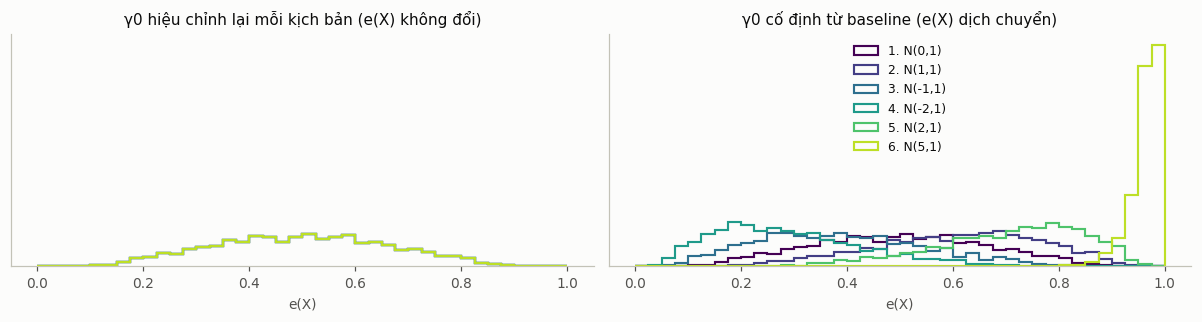

In [3]:
rows = []
for fix in (False, True):
    for k in NAMES:
        s = LocationSimulation(k, n=N, seed=SEED, gamma=GAMMA, fix_gamma0=fix)
        d = diagnostics(s.generate())
        rows.append({"cách": "hiệu chỉnh lại mỗi kịch bản" if not fix else "cố định từ baseline",
                     "kịch bản": SHORT[k], "gamma0": s.gamma0, **d})
chk = pd.DataFrame(rows)
display(chk.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.0), sharey=True)
for ax, fix, ttl in zip(axes, (False, True), ("γ0 hiệu chỉnh lại mỗi kịch bản (e(X) không đổi)", "γ0 cố định từ baseline (e(X) dịch chuyển)")):
    for k, col in zip(NAMES, plt.cm.viridis(np.linspace(0, 0.9, len(NAMES)))):
        e = LocationSimulation(k, n=N, seed=SEED, gamma=GAMMA, fix_gamma0=fix).generate()["e"]
        ax.hist(e, bins=np.linspace(0, 1, 41), histtype="step", color=col, lw=1.4, label=SHORT[k])
    ax.set_title(ttl); ax.set_xlabel("e(X)"); ax.set_yticks([])
axes[1].legend(frameon=False, fontsize=8, loc="upper center")
fig.tight_layout(); plt.show()

**Nhận xét.** Khi hiệu chỉnh lại $\gamma_0$ ở từng kịch bản, $\gamma_0$ trôi theo $\mu$ ($-2.5$ ở $\mu=5$, $+1.0$ ở $\mu=-2$) và cả 6 kịch bản cho đúng cùng một kết quả: treated_rate 0.488, max_weight 10.2, ESS/n 0.856, đường $e(X)$ trùng nhau trên hình trái. Cố định $\gamma_0$ thì tỉ lệ treated đi từ 0.28 đến 0.91, ESS/n từ 0.87 xuống 0.27 và $e(X)$ dịch chuyển rõ (hình phải).

**Quyết định:** nhóm 2 dùng `fix_gamma0=True`; chỉ baseline có P(A=1)=50%. Việc treated lệch khỏi 50% ở các kịch bản còn lại chính là mất cân bằng cần khảo sát. Nhóm 1 (`Simulation`) không bị ảnh hưởng.

## 2. Nhìn dữ liệu: $X_2$ và propensity score theo nhóm

Hàng trên: phân phối $X_2$ của nhóm treated và control. Hàng dưới: $e(X)$ thật theo nhóm. Vùng chồng lấp là phần hai màu cùng có mặt.

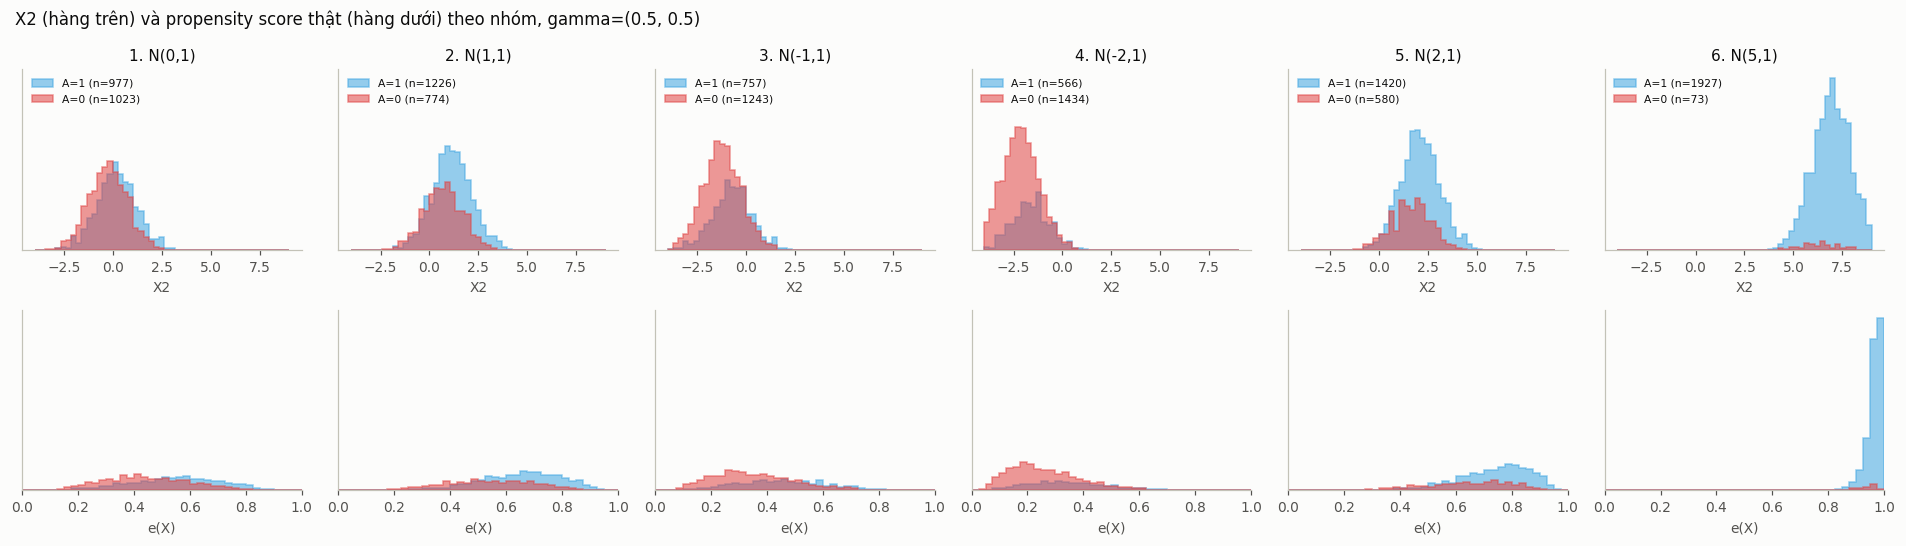

In [4]:
def overview_grid(gamma=GAMMA, n=N, seed=SEED, names=NAMES):
    fig, axes = plt.subplots(2, len(names), figsize=(2.9 * len(names), 5.0), sharey="row")
    for j, k in enumerate(names):
        df = LocationSimulation(k, n=n, seed=seed, gamma=gamma).generate()
        for a, col, lab in [(1, BLUE, "A=1"), (0, RED, "A=0")]:
            axes[0, j].hist(df.loc[df.A == a, "X2"], bins=np.linspace(-4, 9, 50), color=col, alpha=0.55,
                            histtype="stepfilled", edgecolor=col, label=f"{lab} (n={int((df.A==a).sum())})")
            axes[1, j].hist(df.loc[df.A == a, "e"], bins=np.linspace(0, 1, 41), color=col, alpha=0.55,
                            histtype="stepfilled", edgecolor=col)
        axes[0, j].set_title(SHORT[k]); axes[0, j].set_xlabel("X2")
        axes[0, j].legend(frameon=False, fontsize=7, loc="upper left")
        axes[1, j].set_xlabel("e(X)"); axes[1, j].set_xlim(0, 1)
        axes[0, j].set_yticks([]); axes[1, j].set_yticks([])
    fig.suptitle(f"X2 (hàng trên) và propensity score thật (hàng dưới) theo nhóm, gamma={gamma}", x=0.01, ha="left")
    fig.tight_layout(); plt.show()

overview_grid()

**Nhận xét.**
- Khi $\mu_2$ lệch khỏi 0 một nhóm trở thành thiểu số: nhóm control còn 774, 580 và 185 quan sát khi $\mu_2=1,2,5$; nhóm treated còn 757 và 566 khi $\mu_2=-1,-2$. Hai bên đối xứng gương.
- $e(X)$ dồn dần về 1 (hoặc 0). Ở kịch bản 6 gần như toàn bộ $e(X)>0.8$.
- Ngay cả kịch bản 6 hai nhóm **vẫn chồng lấp** (0.6–1.0). Với $\gamma=0.5$ độ dịch logit chỉ là $\gamma\mu=2.5$, chưa đủ để tách rời hoàn toàn như mô tả "disjoint" của đề bài. Phần 6 chạy lại với $\gamma=1$ để thấy trường hợp đó.

## 3. Chẩn đoán overlap khi quét liên tục $\mu_{X_2}$

Quét $\mu_2\in\{-5,\dots,5\}$ (mỗi điểm lặp 300 lần, $n=2000$) với hai mức confounding $\gamma=0.5$ và $\gamma=1$. Mục đích: thấy *xu hướng* theo khoảng cách kỳ vọng, không chỉ 6 điểm rời rạc.

In [5]:
MUS = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]
SWEEP_M = ["ols", "iptw", "iptw_trim", "aipw", "ow"]

def sweep(gamma, reps=300, n=N):
    out = []
    for mu in MUS:
        sim = LocationSimulation(location_name(mu), n=n, seed=SEED, gamma=gamma)
        summ, dg = monte_carlo(sim, reps=reps, methods=SWEEP_M)
        out.append({"mu": mu, **dg.to_dict(),
                    **{f"{m}_{c}": summ.loc[m, c] for m in SWEEP_M for c in ("bias", "rmse", "coverage")}})
    return pd.DataFrame(out).set_index("mu")

t0 = time.time()
SW = {g: sweep((g, g)) for g in (0.5, 1.0)}
print(f"xong sau {time.time()-t0:.0f}s")
display(SW[1.0][["treated_rate", "e_outside", "max_weight", "ess_ratio", "trim_drop"]].round(3).T)

xong sau 112s


mu,-5,-4,-3,-2,-1,0,1,2,3,4,5
treated_rate,0.017,0.041,0.092,0.183,0.324,0.499,0.676,0.816,0.909,0.959,0.983
e_outside,0.613,0.337,0.130,0.034,0.006,0.001,0.006,0.033,0.130,0.336,0.612
max_weight,548.784,341.123,190.535,103.624,55.042,36.515,53.334,101.987,180.592,339.705,603.504
ess_ratio,0.024,0.047,0.103,0.217,0.419,0.553,0.422,0.215,0.103,0.049,0.024
trim_drop,0.926,0.773,0.515,0.253,0.089,0.038,0.088,0.254,0.516,0.772,0.926


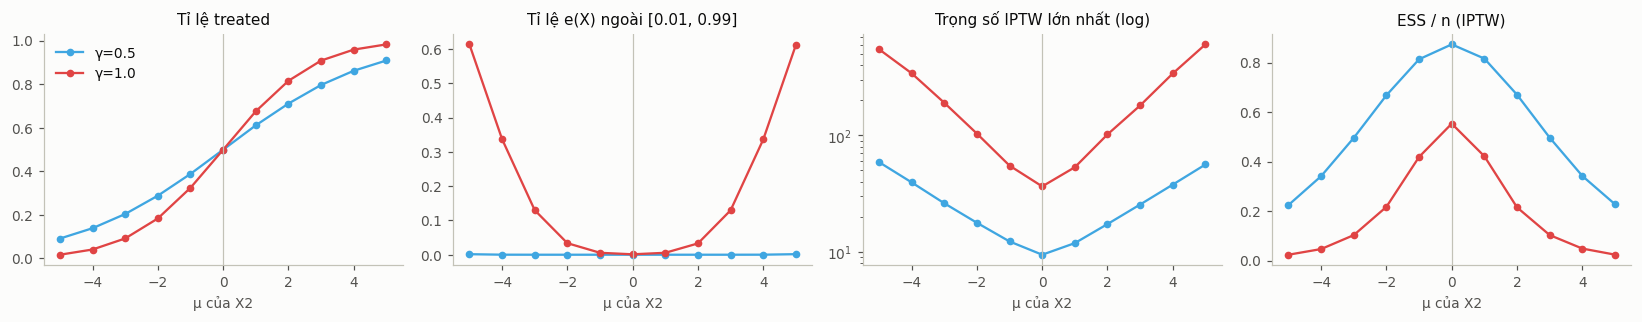

In [6]:
def plot_sweep_diag(SW):
    items = [("treated_rate", "Tỉ lệ treated"), ("e_outside", "Tỉ lệ e(X) ngoài [0.01, 0.99]"),
             ("max_weight", "Trọng số IPTW lớn nhất (log)"), ("ess_ratio", "ESS / n (IPTW)")]
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.0))
    for ax, (c, t) in zip(axes, items):
        for g, col in ((0.5, BLUE), (1.0, RED)):
            ax.plot(SW[g].index, SW[g][c], "-o", ms=4, color=col, label=f"γ={g}")
        ax.set_title(t); ax.set_xlabel("μ của X2"); ax.axvline(0, color="#c3c2b7", lw=0.8)
        if c == "max_weight": ax.set_yscale("log")
    axes[0].legend(frameon=False)
    fig.tight_layout(); plt.show()

plot_sweep_diag(SW)

**Nhận xét.**
- **Chẩn đoán đối xứng quanh $\mu=0$.** Ở $\gamma=1$: tỉ lệ $e(X)\notin[0.01,0.99]$ là 0.1% ($\mu=0$) → 3.3% ($\mu=\pm2$) → 61% ($\mu=\pm5$); ESS/n 0.55 → 0.22 → 0.024; trọng số lớn nhất 37 → ~100 → 550–600; tỉ lệ bị trim (ngưỡng 0.05) 4% → 25% → 93%. Mức xấu đi tăng nhanh, không tuyến tính theo $|\mu|$.
- **RMSE có dạng chữ U** quanh 0. OLS và OW thấp nhất và gần như trùng nhau, IPTW cao nhất, AIPW ở giữa. Từ $\mu=0$ đến $|\mu|=5$ RMSE của IPTW gấp khoảng 2 lần khi $\gamma=0.5$ và khoảng 6 lần khi $\gamma=1$ (≈0.08 → ≈0.47), còn OLS tăng ≈0.05 → ≈0.18.
- **Bias.** Ở $\gamma=0.5$ bias nằm trong ±0.006, cùng cỡ sai số Monte Carlo (SD/√300 ≈ 0.003–0.006), nên các dấu +/− không có ý nghĩa hệ thống. Ở $\gamma=1$ chỉ IPTW chệch rõ ở $|\mu|=5$ (≈0.08–0.09); các phương pháp còn lại |bias| ≲ 0.02.
- **Độ phủ CI.** $\gamma=0.5$: ≥ 0.92 ở mọi $\mu$. $\gamma=1$: IPTW và AIPW rơi xuống khoảng 0.76–0.84 tại $|\mu|=5$, trong khi OLS ≈ 0.94 và OW ≥ 0.95.

## 4. Phân tích từng kịch bản (một lần chạy)

`inspect_case(name)` cho một kịch bản: chẩn đoán overlap, phân phối $X_2$ và $e(X)$, bảng balance trước/sau IPTW, Love plot, ESS, và forest plot ATE ước lượng kèm CI 95% của các phương pháp. Tham số `trim` (với `trim_mode="drop"`) để xem sau trimming.

In [7]:
def love_plot(table, ax=None, title="Covariate balance trước và sau gán trọng số", threshold=0.1):
    t = table.reindex(table["smd_before"].abs().sort_values(ascending=False).index)
    k, ypos = len(t), np.arange(len(t))
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(5.2, max(2.0, 0.5 * k + 1.2)))
    for s in (-threshold, threshold): ax.axvline(s, color=RED, lw=1, ls="--")
    ax.axvline(0, color=RED, lw=0.8, alpha=0.6)
    ax.scatter(t["smd_before"], ypos, color=GREEN, s=45, zorder=3, label="Trước weighting")
    ax.scatter(t["smd_after"], ypos, color=BLUE, s=45, zorder=3, label="Sau IPTW")
    ax.set_yticks(ypos); ax.set_yticklabels(t.index); ax.set_ylim(k - 0.5, -0.5)
    ax.set_xlabel("Standardized mean difference"); ax.set_title(title)
    ax.legend(frameon=False, loc="best", fontsize=8)
    if own: plt.tight_layout(); plt.show()

def forest(ax, res, truth, title="ATE ước lượng và CI 95%"):
    r = res.reindex(METHODS_ALL)
    y = np.arange(len(r))
    for i, (m, row) in enumerate(r.iterrows()):
        if np.isfinite(row["se"]):
            ax.plot([row["lo"], row["hi"]], [i, i], color=MCOL[m], lw=2)
        ax.scatter(row["est"], i, color=MCOL[m], s=40, zorder=3)
    ax.axvline(truth, color=INK, lw=1, ls="--")
    ax.set_yticks(y); ax.set_yticklabels(r.index); ax.set_ylim(len(r) - 0.5, -0.5)
    ax.set_xlabel("ATE"); ax.set_title(title)

def inspect_case(name, n=N, seed=SEED, gamma=GAMMA, trim=None, trim_mode="drop"):
    sim = LocationSimulation(name, n=n, seed=seed, gamma=gamma)
    df = sim.generate()
    print(f"Kịch bản: {SHORT[name]} | {sim.description} | n={n}, gamma={gamma}, gamma0={sim.gamma0:.2f}, ATE thật={sim.ate}")
    display(Simulation.summary(df).round(3).to_frame("giá trị").T)

    fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))
    for a, col, lab in [(1, BLUE, "A=1"), (0, RED, "A=0")]:
        axes[0].hist(df.loc[df.A == a, "X2"], bins=40, color=col, alpha=0.55, histtype="stepfilled", edgecolor=col, label=lab)
        axes[1].hist(df.loc[df.A == a, "e"], bins=np.linspace(0, 1, 41), color=col, alpha=0.55, histtype="stepfilled", edgecolor=col, label=lab)
    axes[0].set_title("Phân phối X2 theo nhóm"); axes[1].set_title("Propensity score e(X) theo nhóm")
    axes[0].set_yticks([]); axes[1].set_yticks([]); axes[1].legend(frameon=False)
    # forest plot (ước lượng PS từ dữ liệu)
    res = estimate_with_se(df, trim=0.05)
    forest(axes[2], res, sim.ate)
    fig.tight_layout(); plt.show()

    if trim is not None:
        print(f"Số quan sát ngoài vùng overlap (trim={trim}, {trim_mode})")
        display(trim_summary(df, trim, trim_mode=trim_mode).to_frame("giá trị").T)

    print("Balance trước / sau gán trọng số IPTW" + (f" (trim={trim})" if trim else ""))
    tbl = check_balance(df, trim=trim, trim_mode=trim_mode)
    display(tbl.round(3))
    love_plot(tbl, title=SHORT[name])
    print("Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW")
    display(effective_sample_size(df, trim=trim, trim_mode=trim_mode).round(3))

    out = res[["est", "se", "lo", "hi"]].copy()
    out["bias"] = out["est"] - sim.ate
    print(f"ATE ước lượng (thật = {sim.ate}); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO")
    display(out.round(3).T)
    return df

### 1. Baseline: $X_2\sim N(0;1)$

Mốc so sánh. Kỳ vọng: overlap tốt, trọng số ổn định, OLS/IPTW/AIPW gần không chệch; chỉ naive chệch do confounding.

Kịch bản: 1. N(0,1) | X1~N(0;1), X2~N(0;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.488,0.088,0.938,0.0,9.651,0.867


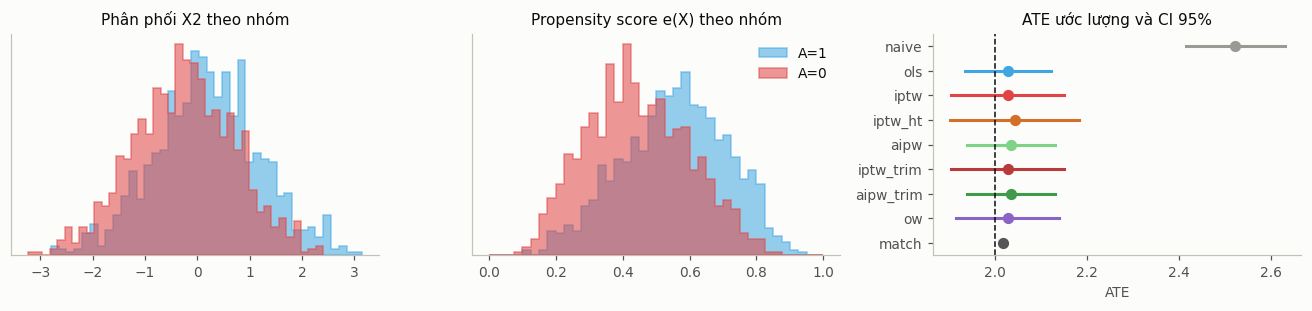

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.534,1.155,False,0.051,1.149,True
X2,0.452,1.084,False,-0.037,1.129,True


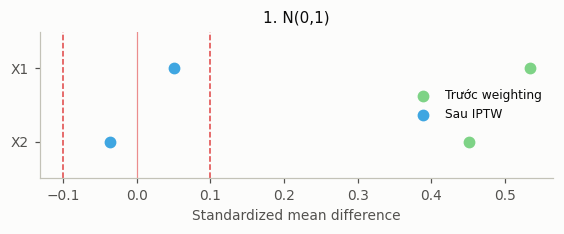

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1734.264,0.867
treated (A=1),977,977,834.721,0.854
control (A=0),1023,1023,900.303,0.880


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.522,2.027,2.027,2.042,2.034,2.027,2.034,2.027,2.017
se,0.055,0.048,0.063,0.072,0.049,0.063,0.049,0.057,NaN
lo,2.415,1.934,1.904,1.902,1.939,1.904,1.939,1.915,NaN
hi,2.630,2.120,2.150,2.182,2.130,2.150,2.130,2.139,NaN
bias,0.522,0.027,0.027,0.042,0.034,0.027,0.034,0.027,0.017


In [8]:
df1 = inspect_case("loc_baseline")

**Nhận xét.** Mốc so sánh. Trước weighting SMD của X1, X2 là 0.53 và 0.45 (mất cân bằng do confounding); sau IPTW còn 0.05 và −0.04, cả hai đạt cân bằng. ESS/n = 0.87, trọng số lớn nhất 9.7. Naive chệch +0.52 (CI không chứa 2); OLS, IPTW, AIPW, OW đều cách 2 chưa tới 0.04 và CI chứa 2.

### 2. Khác biệt vừa, hướng dương: $X_2\sim N(1;1)$

Kỳ vọng: overlap thu hẹp nhẹ, vẫn không chệch, SE của IPTW nhích lên.

Kịch bản: 2. N(1,1) | X1~N(0;1), X2~N(1;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.613,0.138,0.962,0.0,9.634,0.829


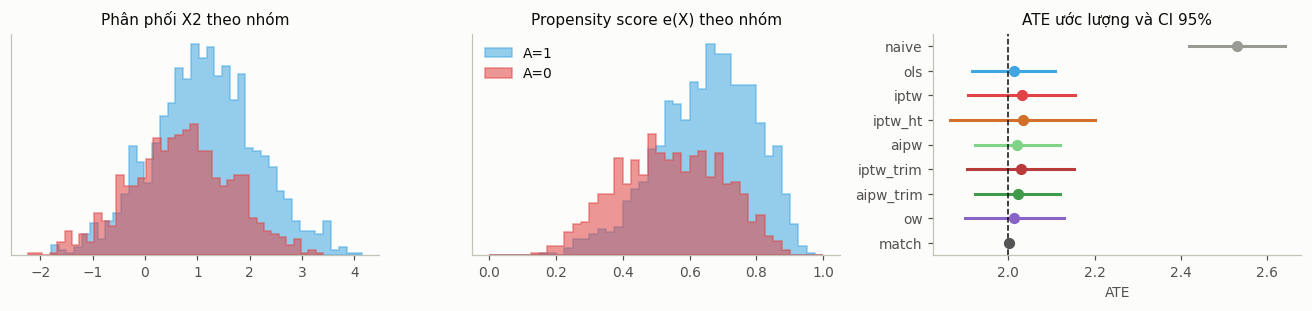

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.579,1.112,False,0.114,1.091,False
X2,0.455,1.068,False,-0.015,1.108,True


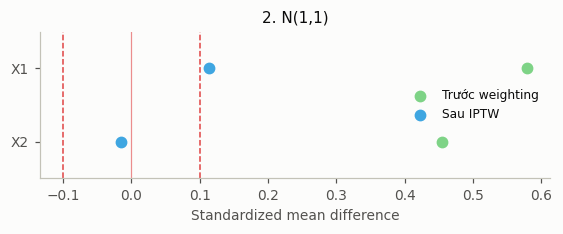

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1657.619,0.829
treated (A=1),1226,1226,1123.255,0.916
control (A=0),774,774,648.355,0.838


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.530,2.013,2.031,2.033,2.021,2.029,2.022,2.015,2.003
se,0.056,0.049,0.063,0.086,0.050,0.063,0.050,0.058,NaN
lo,2.420,1.917,1.908,1.865,1.923,1.905,1.924,1.900,NaN
hi,2.641,2.108,2.155,2.201,2.119,2.152,2.121,2.129,NaN
bias,0.530,0.013,0.031,0.033,0.021,0.029,0.022,0.015,0.003


In [9]:
df2 = inspect_case("loc_pos1")

**Nhận xét.** Treated tăng lên 61%, nhưng trọng số lớn nhất (9.6) và ESS/n (0.83) gần như baseline, SE của IPTW vẫn 0.063. Sau IPTW |SMD| của X1 là 0.114, vượt ngưỡng 0.1 một chút (X2 thì đạt), chênh lệch nhỏ và là dao động của một mẫu. Mọi phương pháp trừ naive cách 2 không quá 0.033.

### 3. Khác biệt vừa, hướng âm: $X_2\sim N(-1;1)$

Kiểm tra tính đối xứng so với kịch bản 2.

Kịch bản: 3. N(-1,1) | X1~N(0;1), X2~N(-1;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.378,0.056,0.902,0.0,9.929,0.811


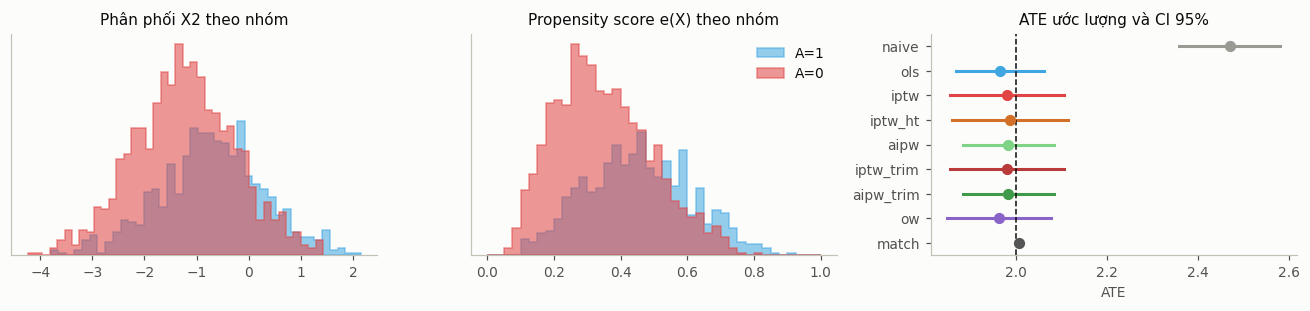

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.464,1.152,False,-0.018,1.146,True
X2,0.522,1.076,False,0.042,1.106,True


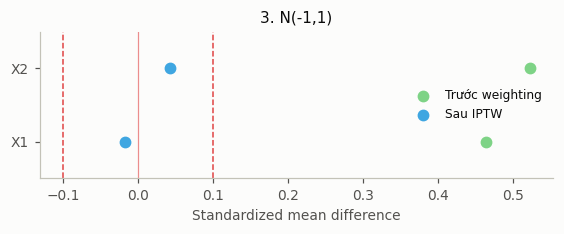

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1621.675,0.811
treated (A=1),757,757,614.405,0.812
control (A=0),1243,1243,1148.998,0.924


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.470,1.965,1.980,1.987,1.983,1.980,1.983,1.963,2.007
se,0.057,0.049,0.064,0.065,0.051,0.064,0.051,0.058,NaN
lo,2.359,1.869,1.855,1.860,1.883,1.855,1.883,1.849,NaN
hi,2.581,2.061,2.105,2.114,2.084,2.105,2.084,2.078,NaN
bias,0.470,-0.035,-0.020,-0.013,-0.017,-0.020,-0.017,-0.037,0.007


In [10]:
df3 = inspect_case("loc_neg1")

**Nhận xét.** Gương của kịch bản 2: treated 38%, ESS/n 0.81, max weight 9.9, balance đạt sau IPTW, mọi estimator ngoài naive cách 2 không quá 0.04. Hiệu năng gần như đối xứng với kịch bản 2.

### 4. Khác biệt lớn, hướng âm: $X_2\sim N(-2;1)$

Kỳ vọng: nhiều $e(X)$ gần 0, trọng số lớn, ESS giảm mạnh.

Kịch bản: 4. N(-2,1) | X1~N(0;1), X2~N(-2;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.283,0.034,0.848,0.0,15.721,0.657


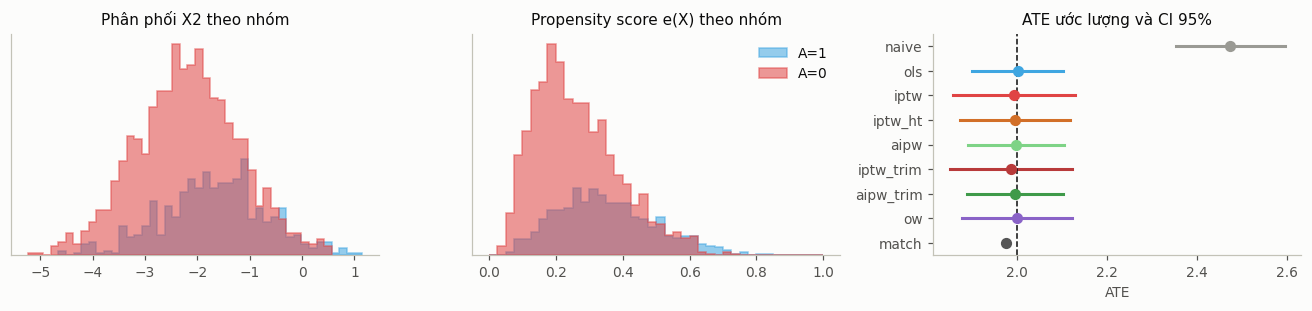

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.413,1.008,False,-0.076,0.979,True
X2,0.510,1.053,False,0.008,1.092,True


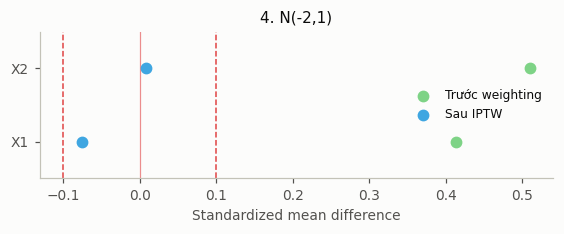

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1314.496,0.657
treated (A=1),566,566,428.740,0.757
control (A=0),1434,1434,1367.826,0.954


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.473,2.002,1.994,1.997,1.998,1.988,1.996,2.001,1.977
se,0.062,0.051,0.069,0.062,0.054,0.069,0.055,0.062,NaN
lo,2.352,1.902,1.859,1.875,1.891,1.853,1.890,1.879,NaN
hi,2.594,2.102,2.129,2.119,2.105,2.123,2.103,2.123,NaN
bias,0.473,0.002,-0.006,-0.003,-0.002,-0.012,-0.004,0.001,-0.023


In [11]:
df4 = inspect_case("loc_neg2")

**Nhận xét.** Treated chỉ còn 28%, $e_{min}=0.034$, trọng số lớn nhất 15.7 và ESS/n giảm còn 0.66. ESS tập trung ở nhóm thiểu số: treated 0.76 so với control 0.95. Chưa có $e(X)$ nào ngoài [0.01, 0.99]. Balance vẫn đạt (|SMD| sau ≤ 0.08), SE của IPTW 0.069 (tăng ~10% so với baseline), các ước lượng của OLS/IPTW/AIPW/OW trong khoảng 1.99–2.00.

### 5. Khác biệt lớn, hướng dương: $X_2\sim N(2;1)$

Kỳ vọng: tương đương kịch bản 4 nhưng bất ổn ở nhóm control (e gần 1).

Kịch bản: 5. N(2,1) | X1~N(0;1), X2~N(2;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.71,0.209,0.976,0.0,15.235,0.681


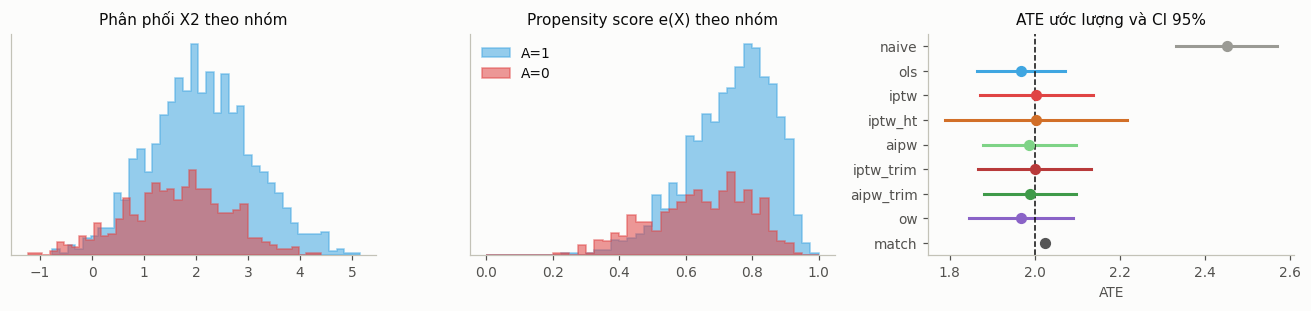

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.472,1.049,False,-0.007,1.023,True
X2,0.478,1.010,False,0.013,1.082,True


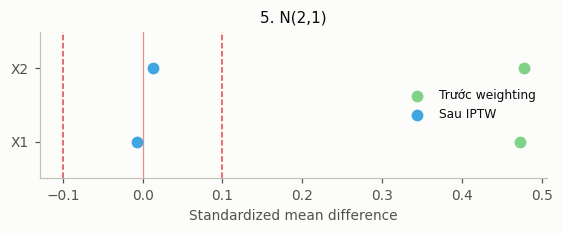

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1361.573,0.681
treated (A=1),1420,1420,1354.442,0.954
control (A=0),580,580,454.551,0.784


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.452,1.967,2.004,2.003,1.987,2.000,1.989,1.968,2.024
se,0.061,0.053,0.068,0.109,0.056,0.068,0.056,0.063,NaN
lo,2.332,1.863,1.871,1.789,1.878,1.867,1.880,1.846,NaN
hi,2.571,2.070,2.136,2.217,2.096,2.132,2.098,2.091,NaN
bias,0.452,-0.033,0.004,0.003,-0.013,-0.000,-0.011,-0.032,0.024


In [12]:
df5 = inspect_case("loc_pos2")

**Nhận xét.** Gương của kịch bản 4 nhưng nhóm thiểu số là control (n=580, ESS/n 0.78 so với treated 0.95). Max weight 15.2, ESS/n 0.68. Điểm đáng chú ý là SE của Horvitz-Thompson 0.109 so với 0.068 của IPTW chuẩn hóa. Các ước lượng còn lại cách 2 không quá 0.033.

### 6. Khác biệt rất lớn: $X_2\sim N(5;1)$

Kỳ vọng: vi phạm positivity nặng, trọng số cực lớn, ESS gần 0.

Kịch bản: 6. N(5,1) | X1~N(0;1), X2~N(7;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.964,0.763,0.998,0.066,68.674,0.133


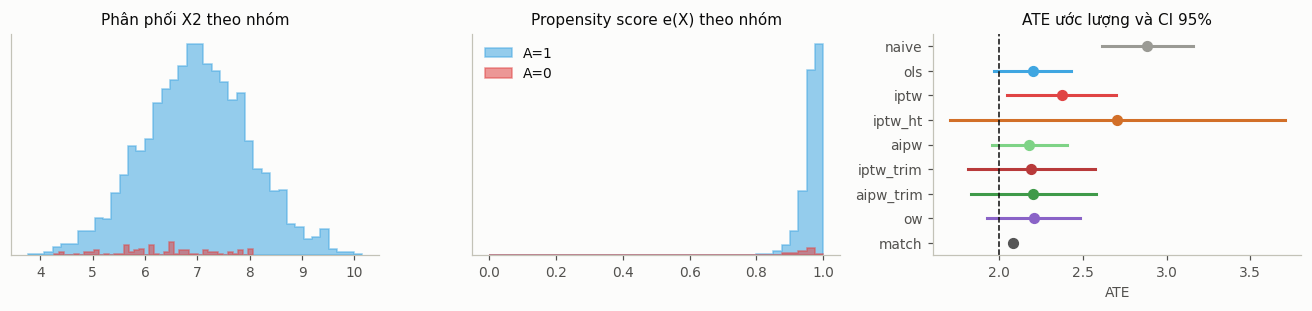

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.689,1.194,False,0.336,1.354,False
X2,0.688,1.080,False,0.304,1.228,False


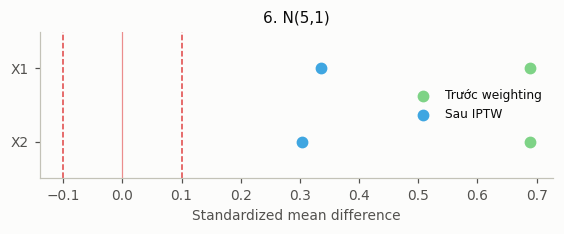

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,266.549,0.133
treated (A=1),1927,1927,1925.359,0.999
control (A=0),73,73,54.427,0.746


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.884,2.199,2.372,2.705,2.180,2.192,2.204,2.206,2.084
se,0.138,0.118,0.166,0.510,0.114,0.193,0.190,0.141,NaN
lo,2.613,1.968,2.047,1.705,1.957,1.813,1.830,1.929,NaN
hi,3.155,2.430,2.697,3.706,2.403,2.571,2.577,2.483,NaN
bias,0.884,0.199,0.372,0.705,0.180,0.192,0.204,0.206,0.084


In [13]:
df6 = inspect_case("loc_pos5")

**Nhận xét.** Đây là kịch bản duy nhất mà dấu hiệu rõ ràng ngay trong một mẫu: treated 91%, chỉ còn 185 control (ESS 142), ESS/n toàn mẫu 0.28, $e_{min}=0.54$. **IPTW không còn cân bằng được hiệp biến**: sau weighting |SMD| X1 = 0.13, X2 = 0.22 và VR 1.2–1.25. SE tăng so với baseline: OLS 0.048 → 0.079, IPTW 0.063 → 0.106, HT 0.072 → 0.250. Trong mẫu này IPTW ước lượng 2.24 (CI 2.04–2.45 không chứa 2) và HT 2.38, trong khi OLS 2.10, AIPW 2.12, OW 2.10, trim 2.06. Cần nhớ đây chỉ là **một** mẫu; mức chệch thực của IPTW phải xem ở mô phỏng lặp (phần 5, 6).

### Tổng hợp Love plot của 6 kịch bản

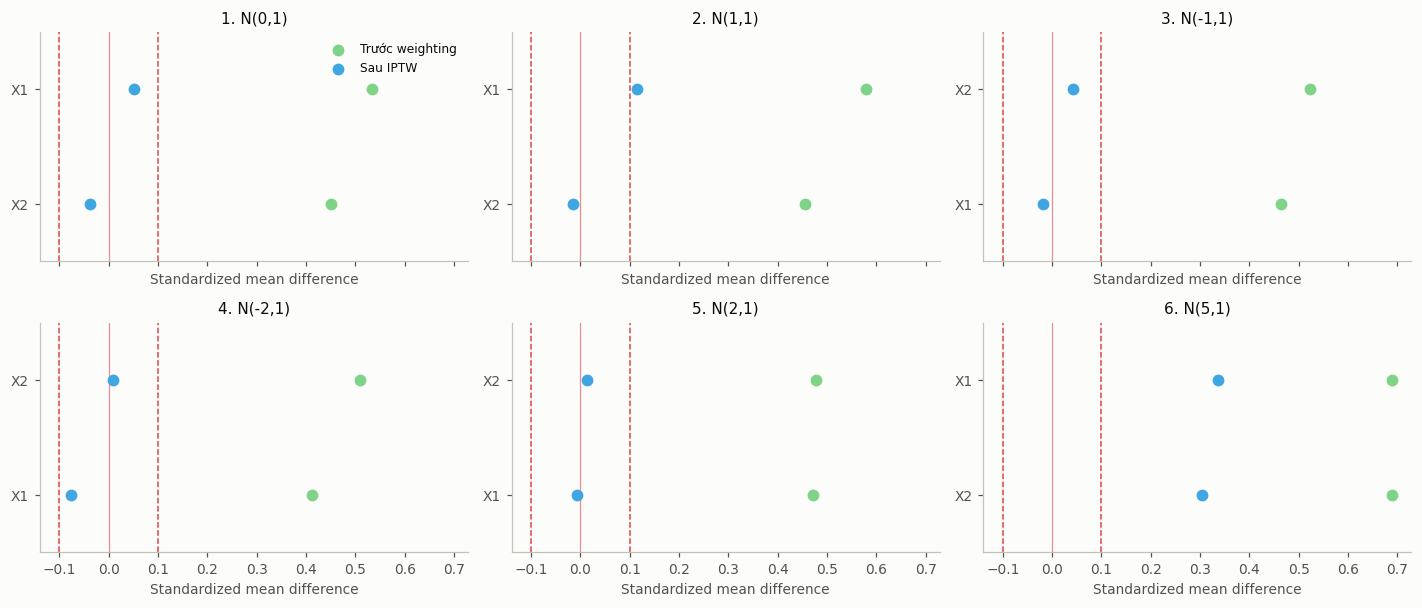

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True)
for ax, k in zip(axes.ravel(), NAMES):
    df = LocationSimulation(k, n=N, seed=SEED, gamma=GAMMA).generate()
    love_plot(check_balance(df), ax=ax, title=SHORT[k])
    ax.get_legend().remove() if ax.get_legend() else None
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

**Nhận xét.** SMD trước weighting ở cả 6 kịch bản đều quanh 0.4–0.6: dịch cả $X_2$ của hai nhóm cùng lúc không làm tăng chênh lệch kỳ vọng *giữa* nhóm treated và control. Cái thay đổi là **tỉ lệ hai nhóm** và **độ cực đoan của $e(X)$**. Sau IPTW 5 kịch bản đầu về dưới 0.1 (chỉ X1 ở kịch bản 2 là 0.114, sát ngưỡng); kịch bản 6 vẫn ở 0.13–0.22. Vì vậy "mất cân bằng sau weighting" là tín hiệu cảnh báo tốt hơn "mất cân bằng trước weighting".

## 5. Mô phỏng lặp: 1000 lần × 6 kịch bản × $n\in\{500, 2000\}$

Mỗi lần lặp sinh dữ liệu mới, ước lượng PS bằng logistic, chạy 9 phương pháp, ghi lại ATE và SE. Các chỉ số:

- **bias** = trung bình ATE ước lượng − 2; **SD**; **RMSE** (RMSE² = bias² + SD²)
- **Độ phủ CI 95%** (Wald, SE theo hàm ảnh hưởng) và **độ rộng CI**; với 1000 lần lặp, độ phủ nằm trong 0.95 ± 0.014 là phù hợp mức danh nghĩa
- chẩn đoán overlap trung bình: tỉ lệ $e(X)\notin[0.01,0.99]$, **trọng số lớn nhất**, **ESS/n**, tỉ lệ bị trim, tỉ lệ bị bỏ khi matching
- `match` không có CI (không có công thức SE đơn giản).

In [15]:
def run_mc(gamma, ns=NS, reps=REPS, names=NAMES):
    res = {}
    for n in ns:
        for k in names:
            sim = LocationSimulation(k, n=n, seed=SEED, gamma=gamma)
            summ, dg, est = monte_carlo(sim, reps=reps, keep_raw=True)
            res[(n, k)] = {"summ": summ, "diag": dg, "est": est}
    return res

def table(res, n, metric, names=NAMES):
    t = pd.DataFrame({SHORT[k]: res[(n, k)]["summ"][metric] for k in names}).T
    return t[METHODS_ALL]

def diag_table(res, n, names=NAMES):
    return pd.DataFrame({SHORT[k]: res[(n, k)]["diag"] for k in names}).T

t0 = time.time()
R = run_mc(GAMMA)
print(f"xong sau {time.time()-t0:.0f}s")

xong sau 96s


### 5.1 Chẩn đoán overlap (trung bình qua 1000 lần lặp)

In [16]:
for n in NS:
    print(f"n = {n}"); display(diag_table(R, n).round(3))

n = 500


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
"1. N(0,1)",0.499,0.000,7.680,0.868,0.000,0.020
"2. N(1,1)",0.611,0.000,9.485,0.812,0.001,0.021
"3. N(-1,1)",0.389,0.000,9.671,0.810,0.001,0.021
"4. N(-2,1)",0.289,0.000,13.858,0.667,0.006,0.026
"5. N(2,1)",0.711,0.000,13.786,0.668,0.006,0.028
"6. N(5,1)",0.963,0.061,90.861,0.098,0.787,0.242


n = 2000


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
"1. N(0,1)",0.500,0.00,9.471,0.873,0.000,0.005
"2. N(1,1)",0.611,0.00,12.197,0.816,0.000,0.006
"3. N(-1,1)",0.389,0.00,12.210,0.815,0.000,0.006
"4. N(-2,1)",0.289,0.00,17.796,0.669,0.004,0.007
"5. N(2,1)",0.711,0.00,17.384,0.672,0.004,0.008
"6. N(5,1)",0.963,0.06,124.632,0.092,0.784,0.063


**Nhận xét ($\gamma=0.5$).**
- Từ baseline đến $\mu=\pm2$: ESS/n 0.87 → 0.67, max weight 9.5 → ~17.5, tỉ lệ bị trim 0.4%. Đến $\mu=5$: ESS/n 0.23, max weight 56.6, 26.8% bị trim, 2.5% quan sát bị matching loại ($n=500$: 9.2%).
- **Tỉ lệ $e(X)\notin[0.01,0.99]$ là chỉ số kém nhạy**: gần 0 cho tới $\mu=5$ (0.2%) dù ESS đã giảm hơn 3 lần. Nên dùng ESS/n và tỉ lệ bị trim ở ngưỡng 0.05 để sàng lọc.
- Hai cỡ mẫu cho cùng xu hướng; ESS/n gần như không đổi theo $n$, còn trọng số lớn nhất nhỏ hơn ở $n=500$ chỉ vì ít quan sát hơn để chạm cực đoan.

### 5.2 Bias, RMSE, độ phủ CI, độ rộng CI (n = 2000)

In [17]:
n = 2000
for m, t in [("bias", "Bias"), ("rmse", "RMSE"), ("coverage", "Độ phủ CI 95%"), ("ci_width", "Độ rộng CI 95%")]:
    print(t); display(table(R, n, m).round(3))

Bias


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.449,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,-0.002,-0.001
"2. N(1,1)",0.452,0.002,0.002,0.002,0.002,0.003,0.002,0.002,0.003
"3. N(-1,1)",0.452,0.000,0.001,0.001,0.001,0.001,0.001,0.001,0.001
"4. N(-2,1)",0.453,-0.003,-0.003,-0.002,-0.002,-0.003,-0.002,-0.003,-0.001
"5. N(2,1)",0.459,0.004,0.004,0.004,0.003,0.003,0.003,0.003,0.001
"6. N(5,1)",0.493,-0.004,0.015,0.025,0.002,-0.010,-0.012,-0.004,0.002


RMSE


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.452,0.047,0.049,0.049,0.048,0.049,0.048,0.047,0.055
"2. N(1,1)",0.456,0.050,0.054,0.056,0.051,0.053,0.051,0.050,0.059
"3. N(-1,1)",0.456,0.050,0.053,0.052,0.052,0.053,0.052,0.050,0.061
"4. N(-2,1)",0.457,0.053,0.059,0.057,0.055,0.058,0.055,0.053,0.065
"5. N(2,1)",0.462,0.052,0.058,0.063,0.055,0.057,0.055,0.052,0.066
"6. N(5,1)",0.515,0.122,0.185,0.306,0.163,0.198,0.198,0.122,0.174


Độ phủ CI 95%


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.00,0.956,0.984,0.997,0.948,0.984,0.949,0.979,NaN
"2. N(1,1)",0.00,0.935,0.980,0.999,0.941,0.978,0.941,0.972,NaN
"3. N(-1,1)",0.00,0.935,0.978,0.980,0.936,0.979,0.935,0.974,NaN
"4. N(-2,1)",0.00,0.948,0.983,0.971,0.948,0.982,0.945,0.972,NaN
"5. N(2,1)",0.00,0.950,0.981,1.000,0.945,0.981,0.944,0.978,NaN
"6. N(5,1)",0.08,0.946,0.941,0.998,0.904,0.952,0.918,0.972,NaN


Độ rộng CI 95%


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.211,0.185,0.240,0.279,0.188,0.240,0.188,0.220,NaN
"2. N(1,1)",0.217,0.189,0.249,0.341,0.194,0.248,0.194,0.225,NaN
"3. N(-1,1)",0.217,0.189,0.249,0.248,0.194,0.248,0.194,0.225,NaN
"4. N(-2,1)",0.233,0.202,0.275,0.247,0.214,0.270,0.213,0.241,NaN
"5. N(2,1)",0.234,0.202,0.275,0.444,0.214,0.270,0.213,0.241,NaN
"6. N(5,1)",0.568,0.469,0.726,2.450,0.563,0.775,0.717,0.569,NaN


### 5.3 Bias, RMSE, độ phủ CI, độ rộng CI (n = 500)

In [18]:
n = 500
for m, t in [("bias", "Bias"), ("rmse", "RMSE"), ("coverage", "Độ phủ CI 95%"), ("ci_width", "Độ rộng CI 95%")]:
    print(t); display(table(R, n, m).round(3))

Bias


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.447,-0.002,-0.000,0.000,-0.002,-0.000,-0.002,-0.002,-0.000
"2. N(1,1)",0.449,-0.003,0.000,0.001,-0.003,0.000,-0.003,-0.003,0.001
"3. N(-1,1)",0.450,-0.001,-0.000,-0.000,-0.001,-0.000,-0.001,-0.001,0.000
"4. N(-2,1)",0.459,0.003,0.002,0.002,0.002,0.003,0.003,0.003,0.005
"5. N(2,1)",0.457,0.001,0.006,0.006,0.002,0.005,0.002,0.001,0.000
"6. N(5,1)",0.501,0.008,0.054,0.079,0.005,0.006,-0.001,0.007,0.010


RMSE


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.460,0.095,0.100,0.099,0.097,0.100,0.097,0.095,0.110
"2. N(1,1)",0.463,0.096,0.104,0.108,0.100,0.103,0.100,0.096,0.113
"3. N(-1,1)",0.463,0.097,0.104,0.101,0.100,0.103,0.100,0.097,0.117
"4. N(-2,1)",0.475,0.105,0.119,0.114,0.111,0.116,0.111,0.105,0.130
"5. N(2,1)",0.473,0.104,0.118,0.130,0.112,0.114,0.110,0.104,0.123
"6. N(5,1)",0.579,0.240,0.354,0.713,0.335,0.380,0.453,0.241,0.307


Độ phủ CI 95%


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.008,0.954,0.985,0.995,0.952,0.985,0.951,0.977,NaN
"2. N(1,1)",0.021,0.945,0.979,0.997,0.944,0.979,0.944,0.977,NaN
"3. N(-1,1)",0.020,0.946,0.983,0.989,0.951,0.983,0.951,0.977,NaN
"4. N(-2,1)",0.040,0.941,0.977,0.974,0.945,0.978,0.941,0.979,NaN
"5. N(2,1)",0.031,0.946,0.976,0.998,0.944,0.974,0.946,0.973,NaN
"6. N(5,1)",0.588,0.933,0.898,0.990,0.845,0.909,0.830,0.971,NaN


Độ rộng CI 95%


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.423,0.371,0.480,0.558,0.375,0.479,0.374,0.439,NaN
"2. N(1,1)",0.434,0.379,0.496,0.680,0.387,0.493,0.387,0.450,NaN
"3. N(-1,1)",0.434,0.379,0.497,0.497,0.388,0.495,0.387,0.450,NaN
"4. N(-2,1)",0.467,0.405,0.549,0.496,0.426,0.536,0.423,0.483,NaN
"5. N(2,1)",0.468,0.406,0.545,0.886,0.425,0.534,0.424,0.482,NaN
"6. N(5,1)",1.139,0.916,1.274,4.792,0.995,1.350,1.172,1.120,NaN


### 5.4 Trực quan: Bias · SD · RMSE

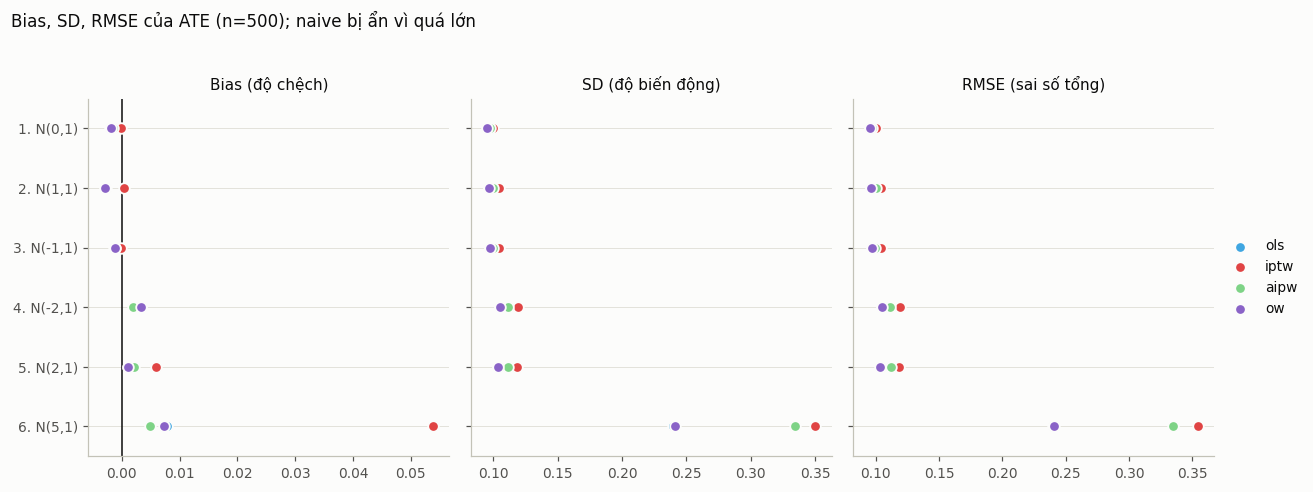

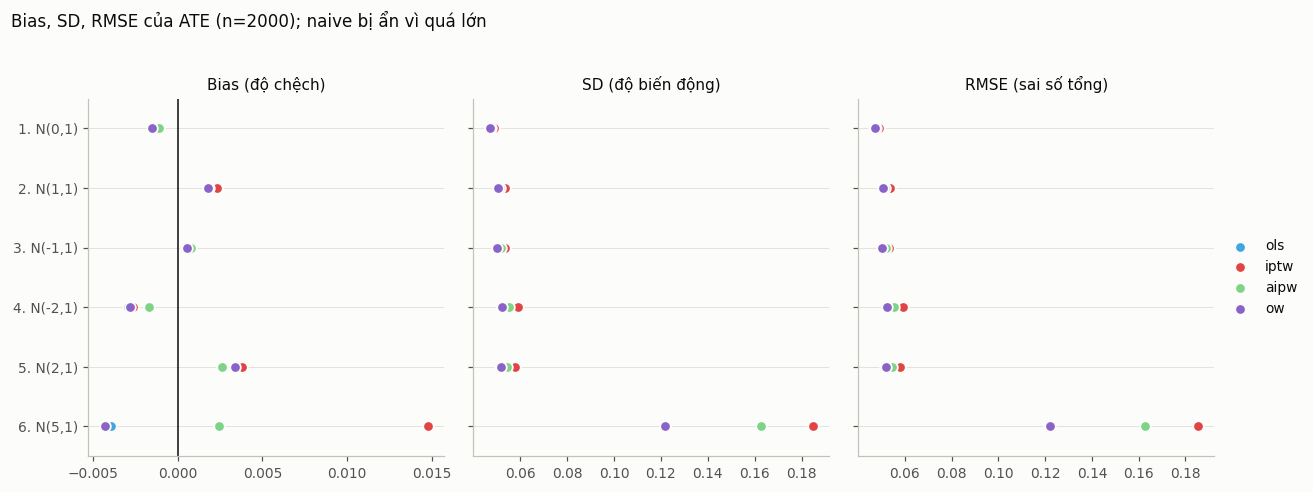

In [19]:
def plot_mc(res, n, methods=("ols", "iptw", "aipw", "ow"), names=NAMES, title=None):
    bias, sd, rmse = table(res, n, "bias"), table(res, n, "sd"), table(res, n, "rmse")
    panels = [("Bias (độ chệch)", bias), ("SD (độ biến động)", sd), ("RMSE (sai số tổng)", rmse)]
    y = np.arange(len(names))
    fig, axes = plt.subplots(1, 3, figsize=(12, 0.45 * len(names) + 1.8), sharey=True)
    for ax, (ttl, tab) in zip(axes, panels):
        for yi in y: ax.axhline(yi, color="#e1e0d9", lw=0.6, zorder=1)
        for m in methods:
            ax.scatter(tab[m], y, s=48, color=MCOL[m], label=m, zorder=3, edgecolor="#fcfcfb", linewidth=1.2)
        if ttl.startswith("Bias"): ax.axvline(0, color=INK, lw=1)
        ax.set_title(ttl); ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y); axes[0].set_yticklabels(tab.index); axes[0].set_ylim(len(names) - 0.5, -0.5)
    axes[2].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.suptitle(title or f"Bias, SD, RMSE của ATE (n={n}); naive bị ẩn vì quá lớn", x=0.01, ha="left", fontsize=11)
    fig.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

for n in NS: plot_mc(R, n)

### 5.5 Độ phủ CI 95% và độ rộng CI

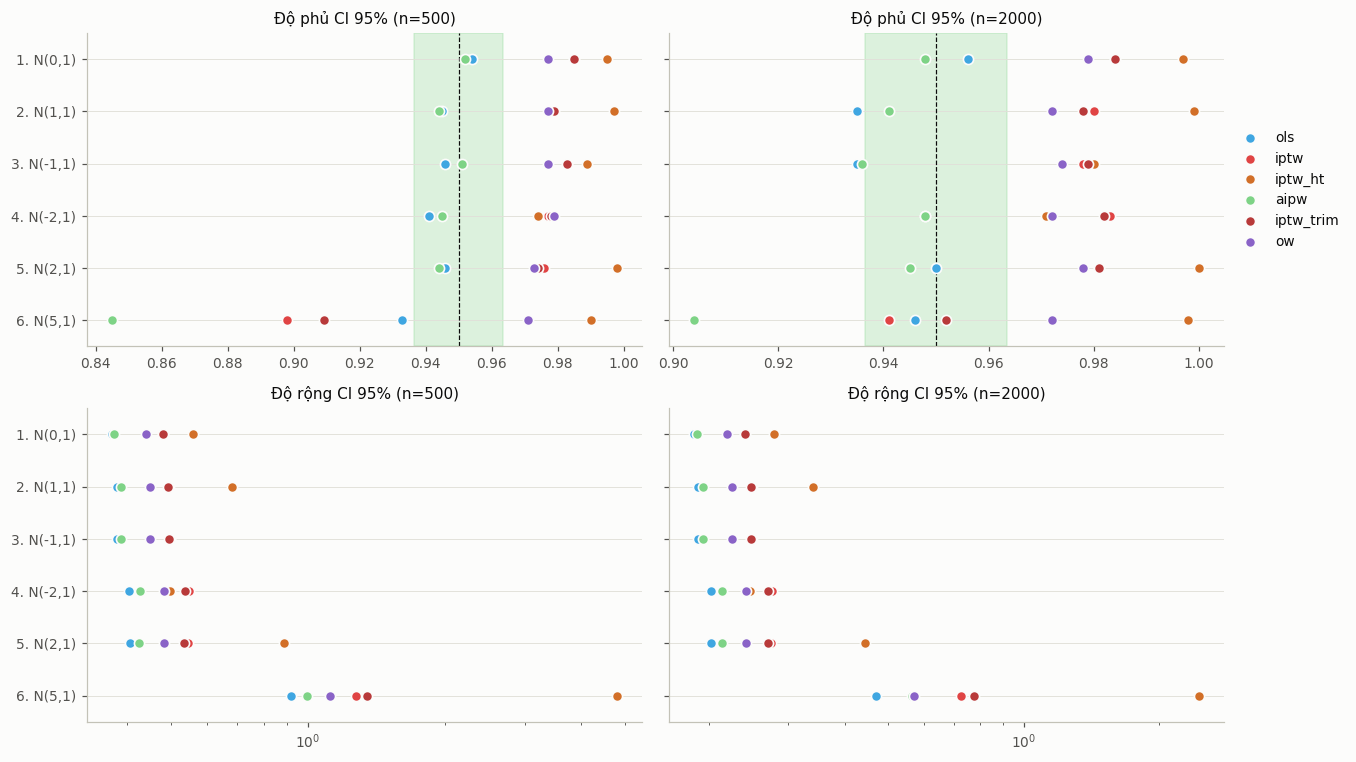

In [20]:
def plot_cov(res, ns=NS, methods=("ols", "iptw", "iptw_ht", "aipw", "iptw_trim", "ow"), reps=REPS, names=NAMES):
    half = 1.96 * np.sqrt(0.95 * 0.05 / reps)
    fig, axes = plt.subplots(2, len(ns), figsize=(6.2 * len(ns), 7.0), sharey="row")
    for j, n in enumerate(ns):
        cov, wid = table(res, n, "coverage"), table(res, n, "ci_width")
        y = np.arange(len(names))
        for ax, tab, ttl in ((axes[0, j], cov, f"Độ phủ CI 95% (n={n})"), (axes[1, j], wid, f"Độ rộng CI 95% (n={n})")):
            for yi in y: ax.axhline(yi, color="#e1e0d9", lw=0.6, zorder=1)
            for m in methods:
                ax.scatter(tab[m], y, s=44, color=MCOL[m], label=m, zorder=3, edgecolor="#fcfcfb", linewidth=1.1)
            ax.set_title(ttl); ax.set_yticks(y); ax.set_yticklabels(tab.index); ax.set_ylim(len(names) - 0.5, -0.5)
            ax.grid(axis="y", visible=False)
        axes[0, j].axvspan(0.95 - half, 0.95 + half, color="#7ED386", alpha=0.25, zorder=0)
        axes[0, j].axvline(0.95, color=INK, lw=0.8, ls="--")
        axes[1, j].set_xscale("log")
    axes[0, -1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.tight_layout(); plt.show()

plot_cov(R)

**Nhận xét ($\gamma=0.5$).**
- **OLS và AIPW** đạt mức danh nghĩa tới $\mu=\pm2$ (0.935–0.956); ở kịch bản 6 AIPW rơi xuống 0.927 ($n=2000$) và 0.905 ($n=500$).
- **IPTW, HT, OW phủ quá mức** (0.97–1.00) ở kịch bản 1–5: CI rộng hơn cần thiết vì SE theo hàm ảnh hưởng không tính phần ước lượng PS (đây là hạn chế đã nêu của `evaluation.py`, không phải ưu điểm của phương pháp). HT phủ 1.000 với CI rộng nhất.
- **Độ rộng CI tăng theo $|\mu|$**: ở $n=2000$, OLS 0.185 → 0.202 ($\mu=\pm2$) → 0.310 ($\mu=5$); IPTW 0.240 → 0.275 → 0.472; HT 0.279 → 0.444 → 1.209.
- **HT không đối xứng:** ở $\mu=-2$ CI rộng 0.247 nhưng ở $\mu=+2$ rộng 0.444. HT nhân trọng số trực tiếp với Y chưa trừ trung bình, nên độ biến động phụ thuộc cả vị trí của Y (trung bình Y dịch theo $\beta_2\mu$); các estimator Hajek, AIPW, OW, OLS không có hiện tượng này (0.275 so với 0.275).

### 5.6 Phân phối của ATE ước lượng qua 1000 lần lặp

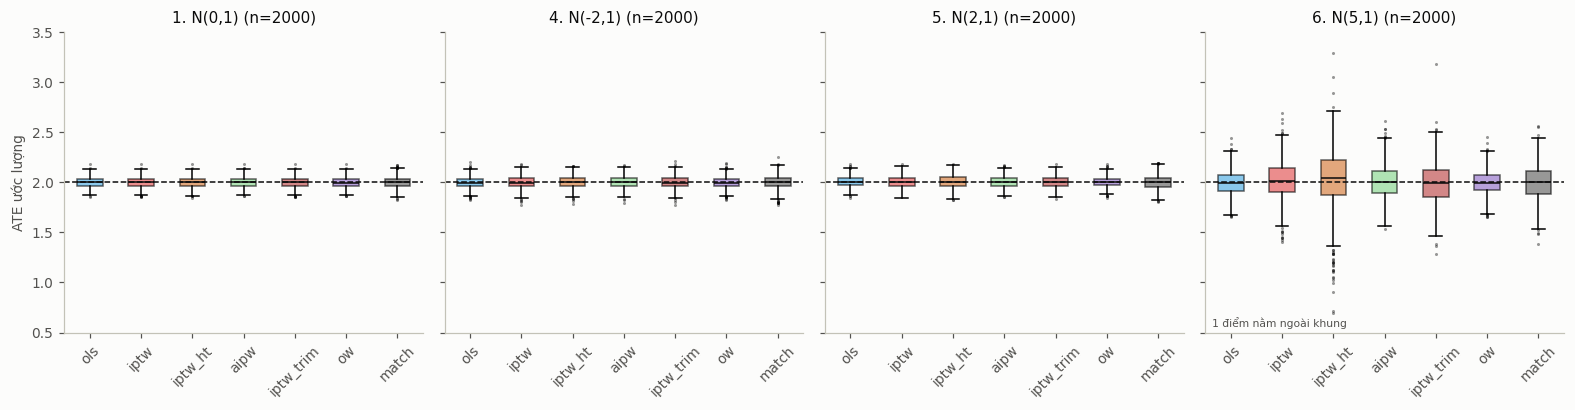

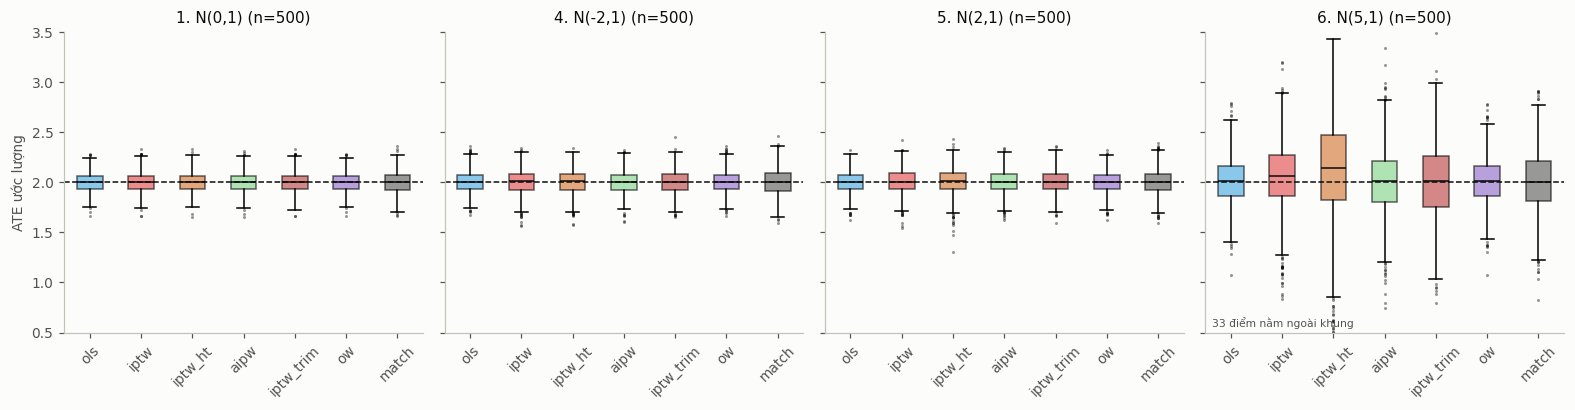

In [21]:
def plot_box(res, n=2000, names=("loc_baseline", "loc_neg2", "loc_pos2", "loc_pos5"), methods=("ols", "iptw", "iptw_ht", "aipw", "iptw_trim", "ow", "match"), truth=2.0):
    fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.8), sharey=True)
    for ax, k in zip(np.atleast_1d(axes), names):
        est = res[(n, k)]["est"][list(methods)]
        bp = ax.boxplot([est[m].dropna() for m in methods], showfliers=True, patch_artist=True,
                        flierprops=dict(marker=".", ms=2, alpha=0.4), medianprops=dict(color=INK))
        ax.set_xticks(range(1, len(methods) + 1)); ax.set_xticklabels(methods)
        for patch, m in zip(bp["boxes"], methods): patch.set_facecolor(MCOL[m]); patch.set_alpha(0.6)
        ax.axhline(truth, color=INK, ls="--", lw=1); ax.set_title(f"{SHORT[k]} (n={n})")
        ax.set_ylim(truth - 1.5, truth + 1.5)
        out = float(((est < truth - 1.5) | (est > truth + 1.5)).to_numpy().sum())
        if out: ax.text(0.02, 0.02, f"{int(out)} điểm nằm ngoài khung", transform=ax.transAxes, fontsize=7, color="#52514e")
        ax.tick_params(axis="x", rotation=45)
    np.atleast_1d(axes)[0].set_ylabel("ATE ước lượng")
    fig.tight_layout(); plt.show()

plot_box(R, 2000)
plot_box(R, 500)

**Nhận xét ($\gamma=0.5$).** Ở kịch bản 1, 4, 5 các hộp hẹp và đều tâm tại 2. Ở kịch bản 6 ($n=2000$) tâm các hộp vẫn ở 2 (không chệch), khác biệt nằm ở độ rộng: OLS và OW hẹp nhất; HT rộng nhất (1000 lần lặp trải từ 1.38 đến 2.46, SD 0.157), IPTW 1.63–2.34 (SD 0.113), AIPW 1.71–2.28 (SD 0.099); matching có hộp rộng hơn OLS rõ rệt. Đuôi nặng thật sự chỉ xuất hiện ở $\gamma=1$ (phần 6).

### 5.7 Heatmap RMSE và hiệu ứng cỡ mẫu

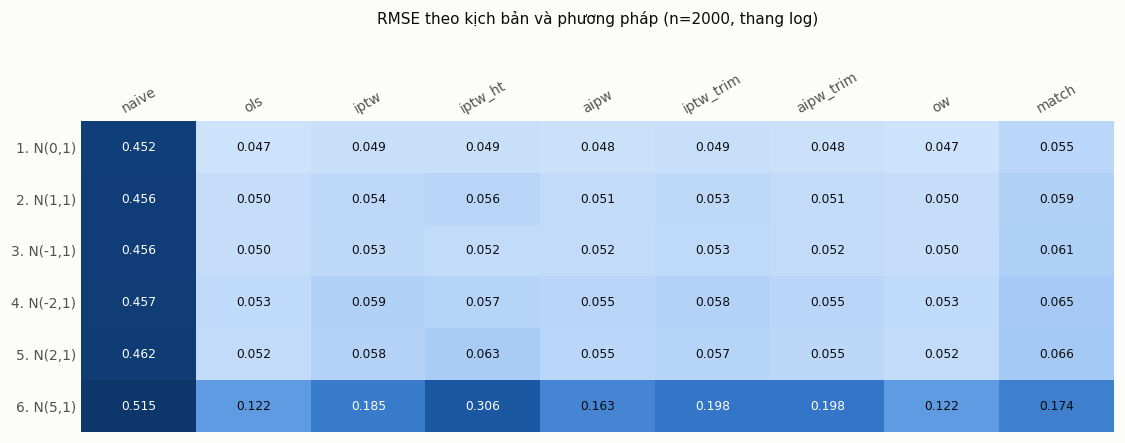

Tỉ số RMSE(n=500)/RMSE(n=2000). Ước lượng ổn định thì ≈ √4 = 2; lệch xa cho thấy phân phối đuôi nặng, hội tụ chậm


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",1.02,2.03,2.05,2.02,2.03,2.04,2.03,2.03,2.00
"2. N(1,1)",1.01,1.91,1.94,1.95,1.94,1.95,1.95,1.91,1.91
"3. N(-1,1)",1.02,1.93,1.95,1.94,1.93,1.95,1.93,1.94,1.94
"4. N(-2,1)",1.04,2.00,2.01,2.01,2.01,2.01,2.01,2.00,1.99
"5. N(2,1)",1.02,2.01,2.04,2.07,2.04,2.01,2.02,2.00,1.87
"6. N(5,1)",1.12,1.97,1.91,2.33,2.06,1.92,2.29,1.98,1.76


In [22]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm
def heatmap(tab, title, fmt="{:.3f}", ax=None):
    cmap = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
    vals = tab.to_numpy(dtype=float)
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(0.9 * tab.shape[1] + 2.2, 0.45 * tab.shape[0] + 1.4))
    norm = LogNorm(vmin=np.nanmin(vals[vals > 0]), vmax=np.nanmax(vals))
    ax.imshow(vals, cmap=cmap, norm=norm, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            if np.isfinite(vals[i, j]):
                ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if norm(vals[i, j]) > 0.55 else INK)
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns, rotation=30)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.grid(False); ax.set_title(title, pad=30)
    if own: plt.tight_layout(); plt.show()

heatmap(table(R, 2000, "rmse"), "RMSE theo kịch bản và phương pháp (n=2000, thang log)")
ratio = table(R, 500, "rmse") / table(R, 2000, "rmse")
print("Tỉ số RMSE(n=500)/RMSE(n=2000). Ước lượng ổn định thì ≈ √4 = 2; lệch xa cho thấy phân phối đuôi nặng, hội tụ chậm")
display(ratio.round(2))

**Nhận xét ($\gamma=0.5$).** RMSE của OLS, IPTW, AIPW, OW giảm gần đúng √4 = 2 lần khi $n$ tăng 4 lần ở mọi kịch bản (1.91–2.18, kể cả kịch bản 6): ước lượng vẫn nhất quán và tăng $n$ bù được phần mất ESS. Naive ≈ 1.0 vì bias không giảm theo $n$. Matching hơi dưới 2 (1.86–1.87 ở kịch bản 5, 6).

## 6. Độ nhạy theo độ mạnh của confounding ($\gamma=1$)

Với $\gamma=0.5$, kể cả $\mu_2=5$ chỉ đẩy $e(X)$ tới khoảng 0.9 chứ chưa "tách rời hoàn toàn" hai nhóm như mô tả của kịch bản 6. Độ mạnh của confounding $\gamma$ nhân với khoảng cách $\mu$ mới quyết định mức vi phạm positivity ($\gamma\mu$ là độ dịch trên thang logit). Chạy lại cả 6 kịch bản với $\gamma=(1,1)$ (các tham số khác giữ nguyên).

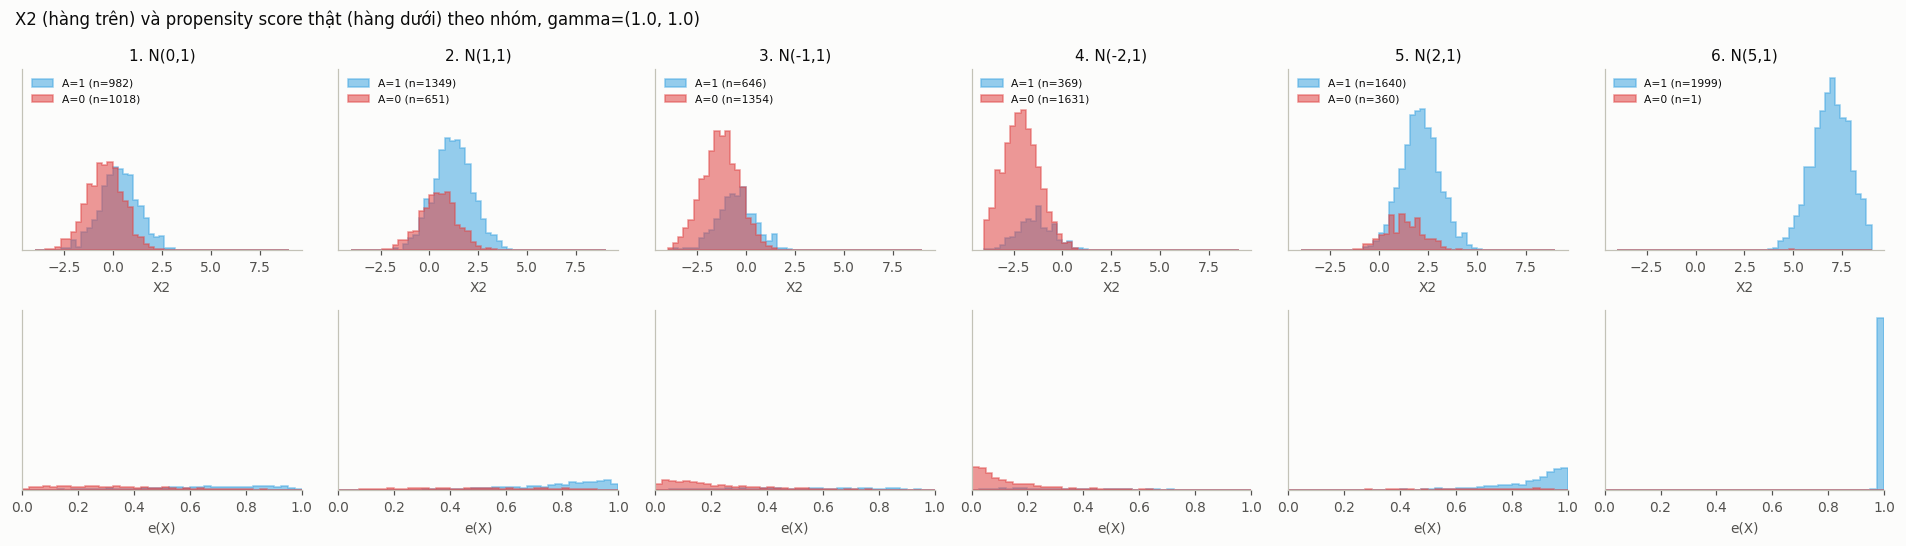

xong sau 62s
n = 500: chẩn đoán overlap


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
"1. N(0,1)",0.499,0.001,2.384100e+01,0.570,0.042,0.055
"2. N(1,1)",0.675,0.006,3.289500e+01,0.454,0.093,0.067
"3. N(-1,1)",0.324,0.006,3.448700e+01,0.446,0.093,0.068
"4. N(-2,1)",0.184,0.033,6.184300e+01,0.256,0.258,0.112
"5. N(2,1)",0.816,0.033,6.008100e+01,0.260,0.257,0.110
"6. N(5,1)",0.998,0.955,3.501234e+10,0.402,0.994,0.862


n = 2000: chẩn đoán overlap


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
"1. N(0,1)",0.499,0.001,3.679800e+01,0.556,0.038,0.020
"2. N(1,1)",0.675,0.006,5.385000e+01,0.424,0.088,0.026
"3. N(-1,1)",0.325,0.006,5.712300e+01,0.418,0.089,0.025
"4. N(-2,1)",0.184,0.033,1.003310e+02,0.220,0.254,0.043
"5. N(2,1)",0.816,0.033,9.833000e+01,0.221,0.254,0.043
"6. N(5,1)",0.998,0.955,6.000134e+09,0.033,0.996,0.741


In [23]:
G2 = (1.0, 1.0)
overview_grid(gamma=G2)
t0 = time.time(); R2 = run_mc(G2); print(f"xong sau {time.time()-t0:.0f}s")
for n in NS:
    print(f"n = {n}: chẩn đoán overlap"); display(diag_table(R2, n).round(3))

In [24]:
for m, t in [("bias", "Bias"), ("rmse", "RMSE"), ("coverage", "Độ phủ CI 95%"), ("ci_width", "Độ rộng CI 95%")]:
    print(f"{t} (γ=1, n=2000)"); display(table(R2, 2000, m).round(3))

Bias (γ=1, n=2000)


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.725,-0.001,0.001,0.001,0.000,-0.000,0.000,-0.001,0.002
"2. N(1,1)",0.742,0.001,0.006,0.005,0.001,0.002,0.001,0.001,0.002
"3. N(-1,1)",0.742,0.000,0.001,-0.002,-0.002,0.002,0.001,0.001,0.004
"4. N(-2,1)",0.778,-0.003,0.008,0.002,-0.000,-0.002,-0.003,-0.003,0.001
"5. N(2,1)",0.786,0.005,0.015,0.013,0.004,0.004,0.004,0.004,0.008
"6. N(5,1)",0.978,-0.021,0.481,-3868660.470,0.290,0.247,0.337,-0.012,0.000


RMSE (γ=1, n=2000)


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.727,0.051,0.080,7.500000e-02,0.062,0.060,0.056,0.052,0.066
"2. N(1,1)",0.744,0.056,0.094,1.120000e-01,0.073,0.068,0.063,0.056,0.080
"3. N(-1,1)",0.744,0.055,0.117,1.100000e-01,0.077,0.065,0.061,0.055,0.075
"4. N(-2,1)",0.781,0.064,0.137,1.120000e-01,0.101,0.080,0.077,0.066,0.103
"5. N(2,1)",0.789,0.065,0.138,1.940000e-01,0.104,0.081,0.076,0.066,0.107
"6. N(5,1)",1.179,0.534,0.987,6.579941e+07,5.291,0.365,0.469,0.566,0.683


Độ phủ CI 95% (γ=1, n=2000)


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.000,0.960,0.975,0.981,0.947,0.984,0.954,0.975,NaN
"2. N(1,1)",0.000,0.944,0.960,0.967,0.934,0.965,0.941,0.976,NaN
"3. N(-1,1)",0.000,0.948,0.959,0.989,0.947,0.971,0.953,0.972,NaN
"4. N(-2,1)",0.000,0.944,0.937,0.977,0.942,0.959,0.930,0.967,NaN
"5. N(2,1)",0.000,0.951,0.924,0.961,0.927,0.962,0.941,0.978,NaN
"6. N(5,1)",0.483,0.785,0.495,0.635,0.243,0.667,0.333,0.837,NaN


Độ rộng CI 95% (γ=1, n=2000)


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",0.205,0.204,0.339,3.500000e-01,0.236,0.284,0.223,0.232,NaN
"2. N(1,1)",0.219,0.215,0.382,4.890000e-01,0.271,0.295,0.241,0.246,NaN
"3. N(-1,1)",0.219,0.215,0.393,3.540000e-01,0.275,0.293,0.240,0.246,NaN
"4. N(-2,1)",0.265,0.250,0.516,4.390000e-01,0.379,0.335,0.294,0.292,NaN
"5. N(2,1)",0.266,0.250,0.511,8.250000e-01,0.376,0.336,0.296,0.292,NaN
"6. N(5,1)",2.000,1.397,1.295,1.798199e+07,0.754,0.971,0.932,1.718,NaN


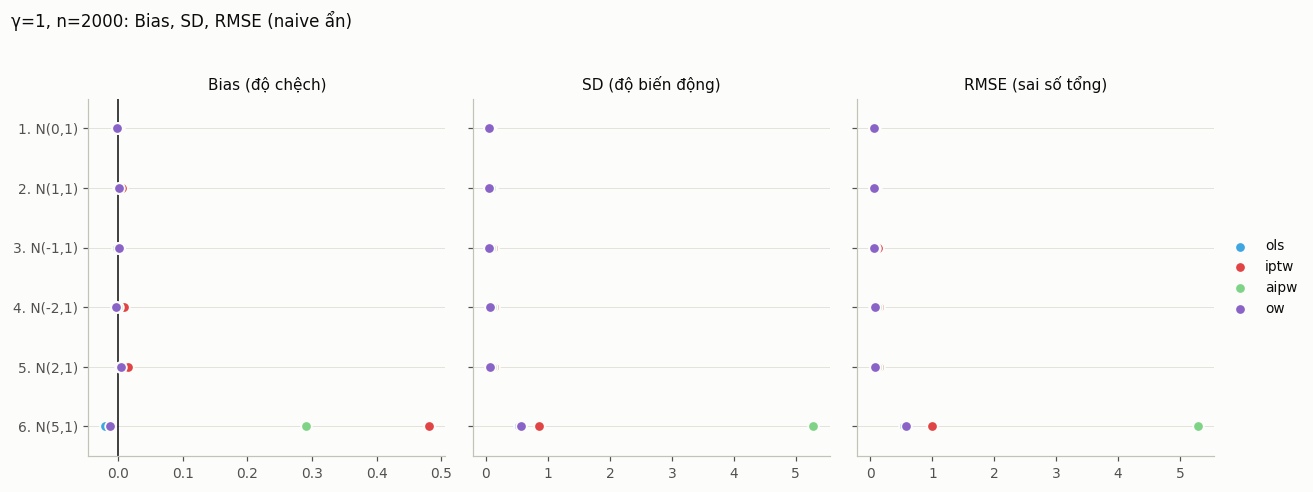

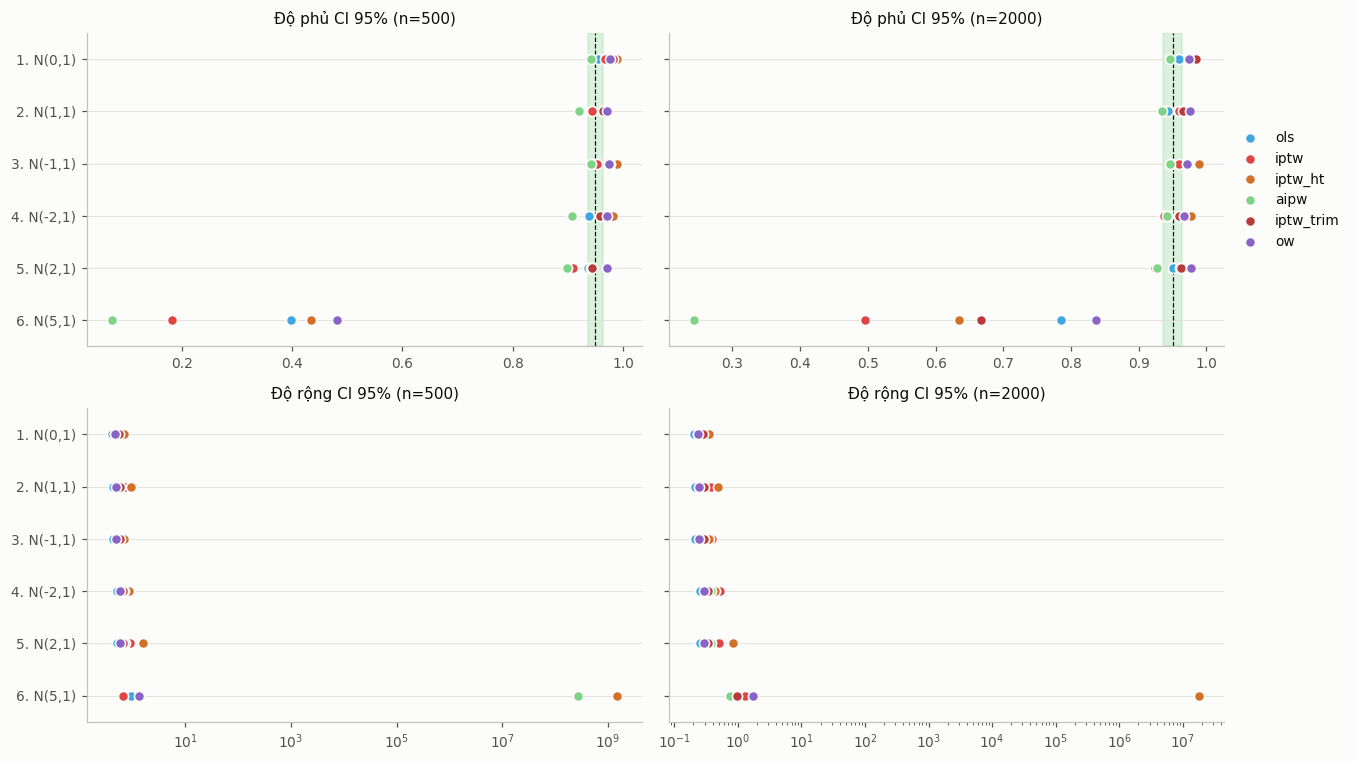

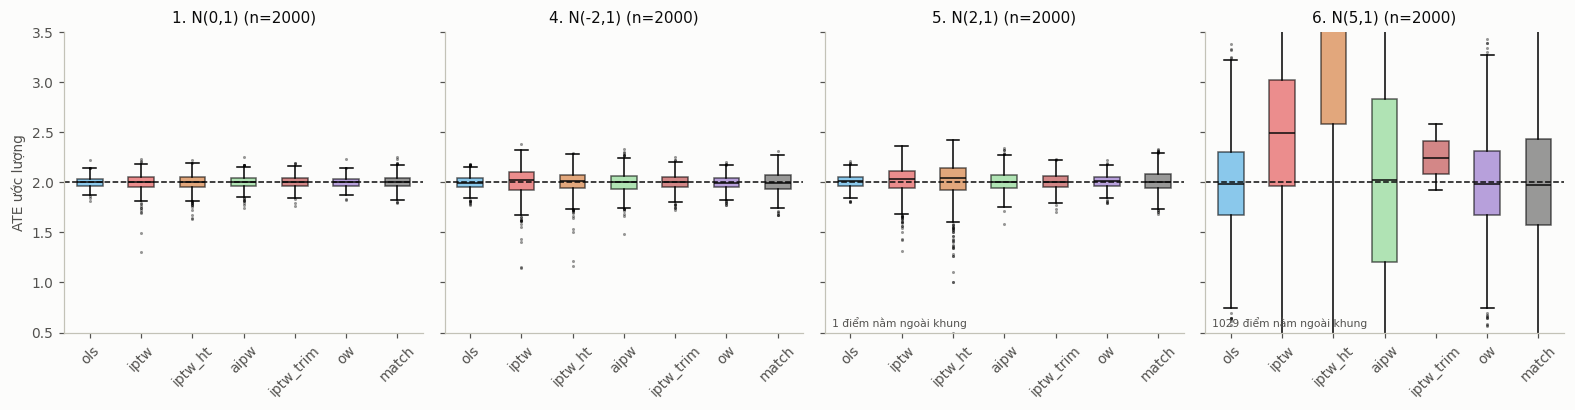

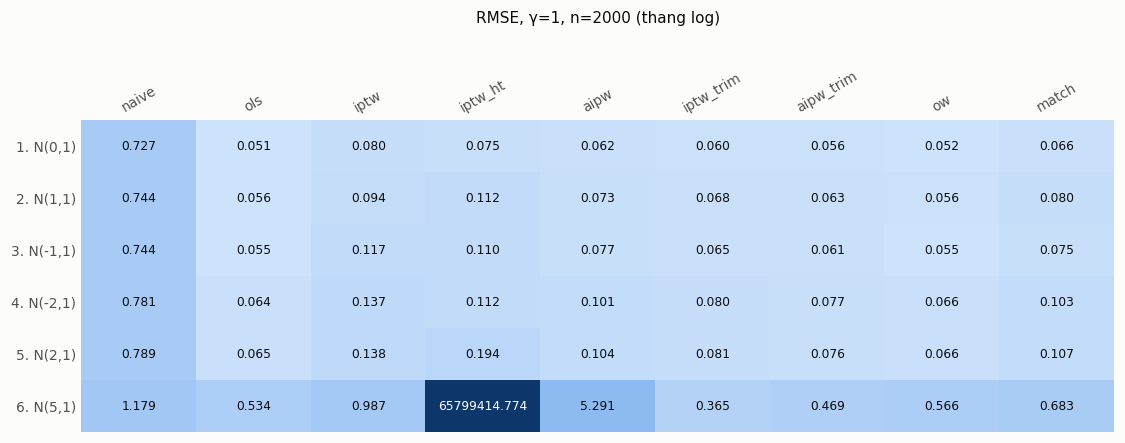

Tỉ số RMSE(n=500)/RMSE(n=2000), γ=1 (≈2 nếu ổn định)


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
"1. N(0,1)",1.01,2.02,1.77,1.96,1.98,2.08,2.08,2.02,1.96
"2. N(1,1)",1.00,2.03,1.92,2.02,2.01,2.03,2.01,2.02,1.83
"3. N(-1,1)",1.01,1.97,1.51,1.40,1.89,1.98,1.96,1.98,1.84
"4. N(-2,1)",1.02,2.03,1.94,2.21,2.10,2.01,2.01,2.02,1.80
"5. N(2,1)",1.01,2.05,1.91,2.83,2.22,2.03,2.06,2.04,1.79
"6. N(5,1)",1.25,1.62,1.44,2529.65,54983758.77,NaN,NaN,1.83,1.54


In [25]:
plot_mc(R2, 2000, title="γ=1, n=2000: Bias, SD, RMSE (naive ẩn)")
plot_cov(R2)
plot_box(R2, 2000, names=("loc_baseline", "loc_neg2", "loc_pos2", "loc_pos5"))
heatmap(table(R2, 2000, "rmse"), "RMSE, γ=1, n=2000 (thang log)")
print("Tỉ số RMSE(n=500)/RMSE(n=2000), γ=1 (≈2 nếu ổn định)")
display((table(R2, 500, "rmse") / table(R2, 2000, "rmse")).round(2))

**Nhận xét ($\gamma=1$, $n=2000$).**
- **Positivity bị vi phạm thật sự ở kịch bản 6:** $e(X)$ ngoài [0.01, 0.99] chiếm 61%, ESS/n = 0.025 (chỉ ~50 quan sát hiệu dụng), trọng số lớn nhất 545, trimming 0.05 loại 93% mẫu, matching loại 28%. Kịch bản 4, 5: 3.3% ngoài biên, ESS/n 0.22.
- **Bias ở kịch bản 6:** naive 0.93, IPTW 0.10, HT 0.04; OLS, AIPW, OW, trimming |bias| ≤ 0.011.
- **RMSE ở kịch bản 6:** OLS 0.180 ≈ OW 0.183 < matching 0.300 < trim 0.334 < AIPW 0.438 < IPTW 0.478 < HT 1.340. IPTW gấp ~2.7 lần OLS, HT gấp ~7 lần. Ở kịch bản 4, 5: OLS 0.064–0.065, AIPW ~0.10, IPTW ~0.14.
- **Độ phủ ở kịch bản 6:** IPTW 0.783, AIPW 0.804, HT 0.845, trim 0.86–0.90, OLS 0.941, OW 0.976. CI rộng: OLS 0.685, OW 0.828, IPTW 1.228, HT 4.359.
- **AIPW giữ được không chệch nhưng không giữ được phương sai** (bias 0.001, SD 0.44): phần hiệu chỉnh $A(Y-\hat\mu_1)/e$ vẫn bị trọng số lớn nhân lên. Với $n=500$ còn tệ hơn: nhóm control chỉ có chục quan sát, mô hình outcome của nhóm đó không ổn định, RMSE AIPW lên tới 4.29 (tỉ số 500/2000 là 9.8, so với ≈2 ở kịch bản khác) và độ phủ 0.47, còn OW vẫn 0.39 và 0.94.
- **OLS tốt nhất vì mô hình outcome ở đây đúng** (tuyến tính, hiệu ứng đồng nhất), nên ngoại suy không gây hại. Kỳ vọng "OLS thất bại khi ngoại suy" chỉ xảy ra khi $m(X)$ phi tuyến hoặc $\tau(X)$ không đồng nhất, các nhóm kịch bản sau cần kiểm tra điều này.
- **Đuôi phân phối ở kịch bản 6** (box plot, 1000 lần lặp): HT trải từ −10.1 đến 3.9, IPTW từ −0.27 đến 3.35, AIPW từ −0.65 đến 4.98, còn OLS và OW hẹp; một số điểm nằm ngoài khung trục (có ghi chú dưới mỗi ô).

## 7. Cách xử lý: trimming, clipping, overlap weighting

Trên kịch bản cực đoan nhất ($\mu_2=5$, $\gamma=1$, $n=2000$) so sánh các cách xử lý ngoại biên $e(X)$:

- **trimming** (`drop`, ngưỡng 0.01/0.05/0.1): bỏ quan sát có $e\notin[t,1-t]$, estimand thành ATE trên vùng overlap;
- **clipping** (`clip`): giữ mọi quan sát, ép $e$ vào $[t,1-t]$ (trọng số không còn là $1/e$ thật);
- **overlap weighting** (ATO): trọng số $1-e$ cho treated và $e$ cho control, không có trọng số nào vượt 1 nên không bùng nổ, nhưng estimand đổi sang quần thể có overlap.

Do $\tau$ đồng nhất nên mọi estimand đều bằng 2 và có thể so bias trực tiếp. Với $\tau(X)$ thay đổi theo $X$, ATE, ATE trên vùng overlap và ATO sẽ khác nhau.

In [27]:
def treat_mc(name, gamma, n=N, reps=500, seed=SEED):
    sim = LocationSimulation(name, n=n, seed=seed, gamma=gamma)
    configs = [("không xử lý", None, "drop"), ("trim 0.01", 0.01, "drop"), ("trim 0.05", 0.05, "drop"),
               ("trim 0.10", 0.10, "drop"), ("clip 0.05", 0.05, "clip"), ("clip 0.10", 0.10, "clip")]
    rec = {c[0]: [] for c in configs}; rec["OW (ATO)"] = []; kept = {c[0]: [] for c in configs}
    from module.methods import estimate_ps
    for _ in range(reps):
        df = sim.generate()
        e_hat = estimate_ps(df, ["X1", "X2"])
        for lab, t, mode in configs:
            try:
                r = estimate_all(df, use_estimated_ps=True, trim=t, trim_mode=mode)
                rec[lab].append((r["iptw"], r["aipw"]))
            except ValueError:
                rec[lab].append((np.nan, np.nan))
            kept[lab].append(1.0 if (t is None or mode == "clip") else overlap_mask(e_hat, t).mean())
        rec["OW (ATO)"].append((estimate_with_se(df, methods=["ow"]).loc["ow", "est"],) * 2)
    rows = []
    for lab, v in rec.items():
        v = np.array(v, float)
        for j, m in enumerate(("iptw", "aipw")):
            if lab.startswith("OW") and m == "aipw": continue
            x = v[:, j]
            rows.append({"cách xử lý": lab, "estimator": "ow" if lab.startswith("OW") else m,
                         "bias": np.nanmean(x) - sim.ate, "sd": np.nanstd(x, ddof=1),
                         "rmse": np.sqrt(np.nanmean((x - sim.ate) ** 2)),
                         "tỉ lệ giữ lại": np.mean(kept[lab]) if lab in kept else 1.0, "n_fail": int(np.isnan(x).sum())})
    return pd.DataFrame(rows)

TR = {g: treat_mc("loc_pos5", (g, g)) for g in (0.5, 1.0)}
for g in TR: print(f"μ2=5, γ={g}"); display(TR[g].round(3))

μ2=5, γ=0.5


,cách xử lý,estimator,bias,sd,rmse,tỉ lệ giữ lại,n_fail
0,không xử lý,iptw,0.014,0.186,0.187,1.000,0
1,không xử lý,aipw,0.002,0.162,0.162,1.000,0
2,trim 0.01,iptw,0.006,0.154,0.154,0.921,0
3,trim 0.01,aipw,-0.000,0.150,0.149,0.921,0
4,trim 0.05,iptw,-0.003,0.198,0.198,0.219,0
5,trim 0.05,aipw,-0.006,0.200,0.200,0.219,0
6,trim 0.10,iptw,-0.026,0.437,0.437,0.038,9
7,trim 0.10,aipw,-0.015,0.798,0.797,0.038,9
8,clip 0.05,iptw,0.329,0.141,0.358,1.000,0
9,clip 0.05,aipw,0.004,0.157,0.156,1.000,0


μ2=5, γ=1.0


,cách xử lý,estimator,bias,sd,rmse,tỉ lệ giữ lại,n_fail
0,không xử lý,iptw,0.503,0.886,1.018,1.000,7
1,không xử lý,aipw,0.224,4.049,4.051,1.000,7
2,trim 0.01,iptw,0.049,0.831,0.831,0.043,113
3,trim 0.01,aipw,-0.429,10.858,10.852,0.043,113
4,trim 0.05,iptw,0.131,0.997,1.003,0.004,293
5,trim 0.05,aipw,-0.272,4.623,4.620,0.004,293
6,trim 0.10,iptw,0.188,1.193,1.203,0.001,375
7,trim 0.10,aipw,3.428,39.536,39.527,0.001,375
8,clip 0.05,iptw,0.933,0.645,1.134,1.000,7
9,clip 0.05,aipw,0.237,4.041,4.044,1.000,7


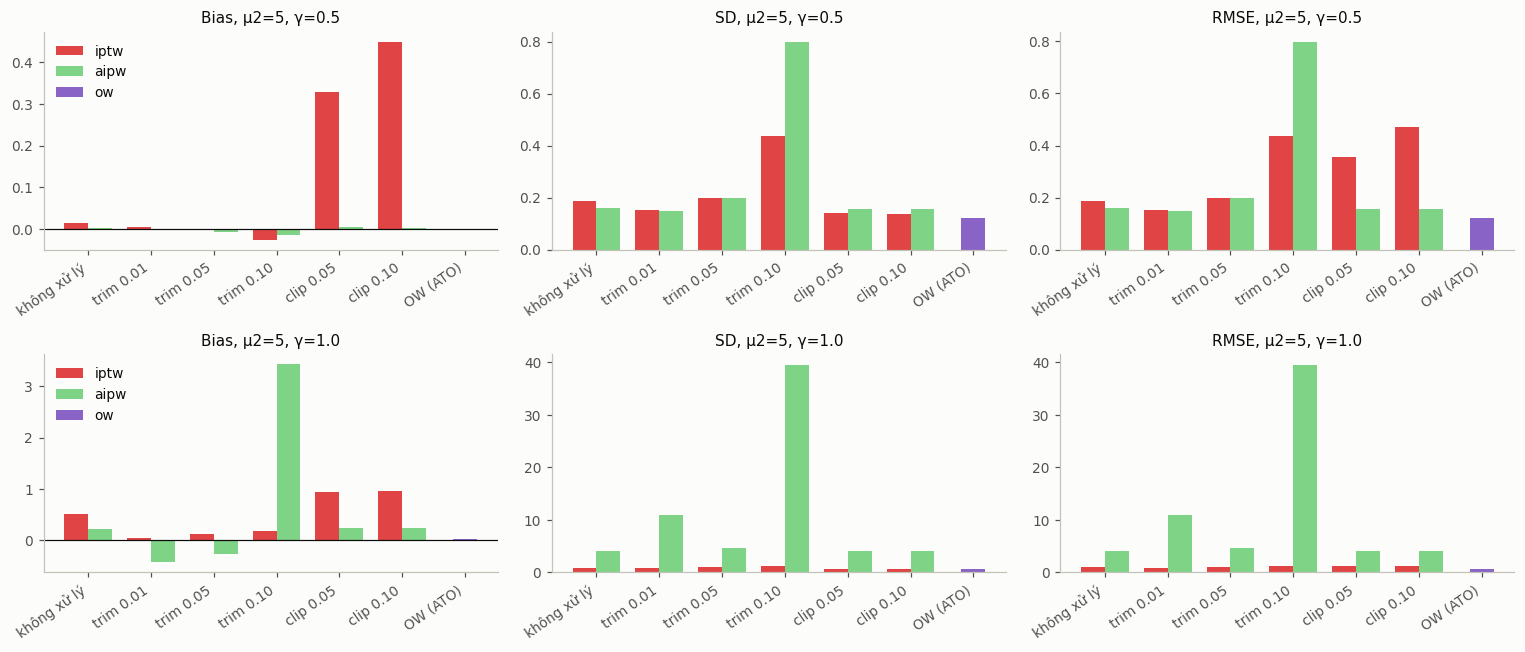

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.0))
for r, g in enumerate((0.5, 1.0)):
    d = TR[g]
    labels = list(dict.fromkeys(d["cách xử lý"]))
    x = np.arange(len(labels)); w = 0.38
    for ax, c, t in zip(axes[r], ("bias", "sd", "rmse"), ("Bias", "SD", "RMSE")):
        for i, (m, col) in enumerate((("iptw", RED), ("aipw", GREEN))):
            s = d[d["estimator"] == m].set_index("cách xử lý").reindex(labels)[c]
            ax.bar(x + (i - 0.5) * w, s, w, color=col, label=m)
        ow = d[d["estimator"] == "ow"]
        ax.bar(labels.index("OW (ATO)"), ow[c].iloc[0], w, color=PURPLE, label="ow")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha="right"); ax.set_title(f"{t}, μ2=5, γ={g}")
        if c == "bias": ax.axhline(0, color=INK, lw=0.8)
    axes[r, 0].legend(frameon=False)
fig.tight_layout(); plt.show()

**Nhận xét ($\mu_2=5$).**
- **$\gamma=0.5$ (overlap còn):** không xử lý đã ổn (IPTW RMSE 0.115). Trim 0.05 (giữ 73%) giảm xuống 0.096; **clipping làm IPTW chệch** +0.105 (clip 0.05) và +0.27 (clip 0.10), RMSE 0.144 và 0.285. AIPW không bị chệch bởi clipping (|bias| ≤ 0.001) nhờ mô hình outcome. OW có RMSE thấp nhất, 0.082.
- **$\gamma=1$ (positivity vi phạm):** không xử lý, IPTW RMSE 0.475. Trim 0.01 (giữ 39%) giảm còn 0.278; trim 0.05 giữ 7.5% (RMSE 0.34 với IPTW, 0.43 với AIPW); trim 0.10 giữ 2.5%, 5/500 lần thất bại và RMSE 0.44–0.64. **Trim quá mạnh lại làm xấu đi** vì còn quá ít quan sát. Clipping làm IPTW chệch 0.72–0.82 (sát naive 0.93), RMSE 0.74–0.85, tệ hơn không xử lý; AIPW sau clipping vẫn ổn (RMSE 0.325, bias 0.02).
- **OW (ATO)** không bias (−0.001), SD 0.177, RMSE 0.177: bằng OLS và chỉ khoảng 37% RMSE của IPTW chưa xử lý. Không cần chọn ngưỡng.
- **Lưu ý estimand.** Trimming và OW trả lời câu hỏi cho quần thể có overlap, không phải toàn bộ ATE. Ở đây $\tau$ đồng nhất nên bias so với 2 là công bằng; khi $\tau(X)$ thay đổi, ATE, ATE trên vùng overlap và ATO sẽ khác nhau và phải báo cáo đúng estimand.

## 8. Kết luận và quy trình đề xuất

### Trả lời câu hỏi nghiên cứu

Khoảng cách kỳ vọng $\mu$ **hầu như không làm chệch** OLS, AIPW, OW và (khi overlap còn) cả IPTW; cái xấu đi là **phương sai, độ phủ CI và độ ổn định của trọng số**, và mức xấu đi phụ thuộc vào tích $\gamma\mu$ (độ dịch trên thang logit) chứ không chỉ $\mu$.

| Mức | Điều kiện | Quan sát |
|---|---|---|
| Ổn định | $\gamma\mu\lesssim 1$ ($\mu=\pm1$, $\gamma=0.5$) | Gần như baseline: ESS/n ≥ 0.8, mọi phương pháp ngoài naive không chệch, SE tăng nhẹ |
| Suy giảm có kiểm soát | $\gamma\mu\approx1$–2.5 | ESS/n 0.2–0.7, trọng số lớn nhất 17–100; RMSE IPTW gấp 1.1–2.7 lần OLS; AIPW giữ bias, SE tăng |
| Vi phạm positivity | $\gamma\mu=5$ | ESS/n 0.025, 61% $e(X)$ ngoài biên; IPTW chệch ~0.1, độ phủ IPTW/AIPW 0.78–0.80; chỉ OLS (mô hình đúng) và OW giữ RMSE ≈ 0.18 và độ phủ ≥ 0.94 |

### Quy trình đề xuất cho vấn đề "lệch vị trí / thiếu overlap"

| Bước | Việc làm | Ngưỡng cảnh báo (từ mô phỏng) |
|---|---|---|
| 1 | Ước lượng PS, vẽ phân phối $\hat e$ theo nhóm | một nhóm chiếm < 20% hoặc $\hat e$ dồn về 0/1 |
| 2 | Tính ESS/n, trọng số lớn nhất, tỉ lệ bị trim ở 0.05 | ESS/n < 0.3 hoặc trim 0.05 loại > 25% mẫu |
| 3 | Kiểm tra balance sau IPTW (SMD, VR) | |SMD| > 0.1 sau weighting |
| 4 | Nếu ổn: dùng AIPW (hoặc OLS nếu tin vào mô hình outcome) | |
| 5 | Nếu cảnh báo: dùng **OW (ATO)** làm ước lượng chính; trimming nhẹ (0.01) và AIPW làm kiểm tra độ bền | tránh clipping với IPTW, tránh trim quá mạnh (≥ 0.10) |
| 6 | Báo cáo đúng estimand (ATE hay ATO / vùng overlap) và CI | |

### Hạn chế cần lưu ý
- Outcome model trong DGP **đúng** (tuyến tính, $\tau$ đồng nhất), nên OLS và AIPW được lợi; kết luận về OLS cần kiểm tra lại ở các nhóm kịch bản phi tuyến.
- CI của IPTW/HT/OW bảo thủ vì bỏ qua sai số ước lượng PS; matching chưa có CI.
- Với 1000 lần lặp, độ phủ có sai số Monte Carlo khoảng ±0.014 quanh 0.95.
- Kịch bản 6 chỉ đạt mức "gần tách rời" khi $\gamma$ đủ lớn (phần 6); ở $\gamma=0.5$ nó chỉ là overlap yếu.

### Hướng làm tiếp
- Kết hợp lệch vị trí với **phương sai khác nhau** giữa hai nhóm và với outcome phi tuyến, để kiểm tra khi nào OLS thất bại và AIPW thực sự cần.
- Thêm CI cho matching (Abadie–Imbens hoặc bootstrap) và PS ước lượng bằng mô hình linh hoạt hơn (GBM) để so với logistic.
- Đưa các ngưỡng cảnh báo ở bảng trên vào module chẩn đoán của pipeline và kiểm tra lại trên dữ liệu thực.